In [2]:
%pip install qutip

   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   --- ------------------------------------ 0.8/9.9 MB 4.9 MB/s eta 0:00:02
   ------- -------------------------------- 1.8/9.9 MB 4.9 MB/s eta 0:00:02
   ----------- ---------------------------- 2.9/9.9 MB 4.9 MB/s eta 0:00:02
   --------------- ------------------------ 3.9/9.9 MB 4.9 MB/s eta 0:00:02
   ------------------- -------------------- 4.7/9.9 MB 4.8 MB/s eta 0:00:02
   ----------------------- ---------------- 5.8/9.9 MB 4.8 MB/s eta 0:00:01
   --------------------------- ------------ 6.8/9.9 MB 4.8 MB/s eta 0:00:01
   ------------------------------- -------- 7.9/9.9 MB 4.8 MB/s eta 0:00:01
   ---------------------------------- ----- 8.7/9.9 MB 4.8 MB/s eta 0:00:01
   -------------------------------------- - 9.4/9.9 MB 4.7 MB/s eta 0:00:01
   ---------------------------------------- 9.9/9.9 MB 4.7 MB/s  0:00:02
Note: you may need to restart the kernel to use updated packages.


# Poisson vs Wigner-Dyson statistics for simple toy model

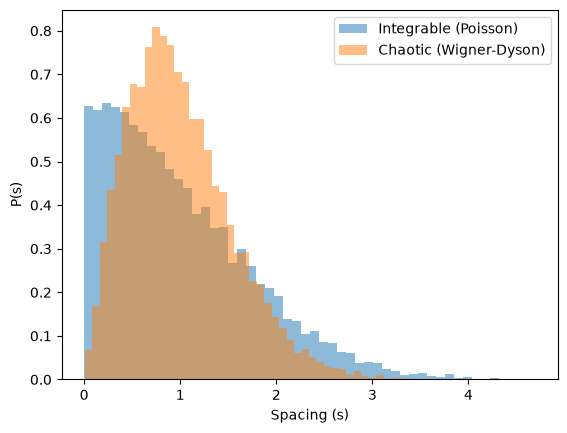

In [1]:
import numpy as np
import matplotlib.pyplot as plt

N = 10000  # Number of matrices to simulate
spacings_integrable = []
spacings_chaotic = []

for _ in range(N):
    # 1. Integrable: Diagonal only
    eps1, eps2 = np.random.normal(0, 1, 2)
    spacings_integrable.append(abs(eps1 - eps2))
    
    # 2. Chaotic: Full real symmetric matrix (GOE)
    v = np.random.normal(0, 1)
    H = np.array([[eps1, v], 
                  [v,    eps2]])
    eigenvalues = np.linalg.eigvalsh(H)
    spacings_chaotic.append(eigenvalues[1] - eigenvalues[0])

# Normalize the data so the mean spacing is 1
spacings_integrable /= np.mean(spacings_integrable)
spacings_chaotic /= np.mean(spacings_chaotic)

# Plotting the result
plt.hist(spacings_integrable, bins=50, density=True, alpha=0.5, label='Integrable (Poisson)')
plt.hist(spacings_chaotic, bins=50, density=True, alpha=0.5, label='Chaotic (Wigner-Dyson)')
plt.xlabel('Spacing (s)')
plt.ylabel('P(s)')
plt.legend()
plt.show()

# Pleak Numerics match with Analytics

In [3]:
from __future__ import annotations

from typing import List, Tuple
import numpy as np
import qutip as qt


# ============================================================
# Local operators
# ============================================================

def op_on_site(op: qt.Qobj, N: int, site: int) -> qt.Qobj:
    if not (0 <= site < N):
        raise ValueError("site out of range")
    ops = [qt.qeye(2)] * N
    ops[site] = op
    return qt.tensor(ops)


def two_site_op(opA: qt.Qobj, opB: qt.Qobj, N: int, i: int, j: int) -> qt.Qobj:
    if i == j:
        raise ValueError("i and j must differ")
    ops = [qt.qeye(2)] * N
    ops[i] = opA
    ops[j] = opB
    return qt.tensor(ops)


# ============================================================
# Hamiltonian
# ============================================================

def kac_factor(N: int, alpha: float) -> float:
    r = np.arange(1, N, dtype=float)
    return np.sum((N - r) / (r ** alpha)) / (N - 1)


def build_H_B_Jz_Jlong(
    N: int,
    Bx: float,
    Jz: float,
    Jx: float,
    alpha: float,
    kac: bool = True,
) -> qt.Qobj:

    if N < 2:
        raise ValueError("N must be >= 2")

    sx, sz = qt.sigmax(), qt.sigmaz()
    H = 0

    # Kac normalization
    if kac:
        Jz = Jz / kac_factor(N, alpha)

    # field x
    for j in range(N):
        H += Bx * op_on_site(sx, N, j)

    # xx nearest neighbor
    for j in range(N - 1):
        H += Jx * two_site_op(sx, sx, N, j, j + 1)

    # zz long-range
    if alpha >= 100:
        for j in range(N - 1):
            H += Jz * two_site_op(sz, sz, N, j, j + 1)
    else:
        for i in range(N):
            for j in range(i + 1, N):
                r = j - i
                H += (Jz / (r ** alpha)) * two_site_op(sz, sz, N, i, j)

    return H


# ============================================================
# Diagonalization
# ============================================================

def diagonalize(H: qt.Qobj):
    evals, evecs = H.eigenstates()
    return np.array(evals), evecs


# ============================================================
# Product states
# ============================================================

# def product_state_angles(thetas: np.ndarray, phis: np.ndarray) -> qt.Qobj:
#     thetas = np.asarray(thetas)
#     phis = np.asarray(phis)

#     if thetas.shape != phis.shape:
#         raise ValueError("shape mismatch")

#     kets = [
#         np.cos(t / 2) * qt.basis(2, 0)
#         + np.exp(1j * p) * np.sin(t / 2) * qt.basis(2, 1)
#         for t, p in zip(thetas, phis)
#     ]

#     return qt.tensor(kets).unit()


# def product_state_x_pm(pm: str) -> qt.Qobj:
#     pm = pm.strip()

#     N = len(pm)
#     thetas = np.full(N, np.pi / 2)
#     phis = np.array([0 if c == "+" else np.pi for c in pm])

#     return product_state_angles(thetas, phis)


def product_state_from_bitstring(bits: str) -> qt.Qobj:
    bits = bits.strip()

    kets = [qt.basis(2, int(b)) for b in bits]
    return qt.tensor(kets).unit()

# ============================================================
# Band mask (Standard Z-basis computational states)
# ============================================================


def band_mask(N, target_band):
    dim = 2**N
    mask = np.zeros(dim, dtype=bool)

    for i in range(dim):
        # Counts the number of set bits (excitations/down-spins) in the Z-basis state
        if bin(i).count("1") == target_band:
            mask[i] = True

    return mask

# ============================================================
# Fidelity from spectrum
# ============================================================

def fidelity_from_spectrum(
    evals: np.ndarray,
    coeffs: np.ndarray,
    times: np.ndarray
) -> np.ndarray:

    weights = np.abs(coeffs) ** 2

    F = np.zeros(len(times))

    for k, t in enumerate(times):
        amp = np.sum(weights * np.exp(-1j * evals * t))
        F[k] = np.abs(amp) ** 2

    return F

# ============================================================
# Compute P_stay(t) in the Z-basis
# ============================================================


def compute_Pstay_z(H, psi0, target_band, times):

    N = int(np.log2(H.shape[0]))

    # No rotation needed — everything stays in the original Z-basis
    # Precompute band mask for the Z-basis
    mask = band_mask(N, target_band)

    # Evolve the state directly with the original Hamiltonian
    result = qt.sesolve(H, psi0, times)

    P = np.zeros(len(times))

    for ti, psi_t in enumerate(result.states):
        # Calculate populations/probabilities in the Z-basis
        probs = np.abs(psi_t.full().flatten()) ** 2
        P[ti] = np.sum(probs[mask])

    return P

In [11]:
np.arange(0, 22, 2)

array([ 0,  2,  4,  6,  8, 10, 12, 14, 16, 18, 20])

In [22]:
from __future__ import annotations
import os
import numpy as np
import pandas as pd
import qutip as qt

# Parameters
N = 10
Jx = 1.0
Bx = 1.0
alpha = 0.2
tmax = 100

# Z-basis state configuration ('1' means spin down/excitation)
psi0string = "01" + "0" * (N - 2)
target_band = psi0string.count("1")
psi0 = product_state_from_bitstring(psi0string)

times = np.arange(0, 100.1, 0.1)
Jz_list = np.arange(0, 22, 2)

# Build directory structure
output_dir = "ED_Data/SectorConfinement"
os.makedirs(output_dir, exist_ok=True)

# Run Simulation while varying Jz
for Jz in Jz_list:
    H = build_H_B_Jz_Jlong(N, Bx, Jz, Jx, alpha, kac=False)
    P_t = compute_Pstay_z(H, psi0, target_band, times)

    # Prepare DataFrame storing the full time evolution for THIS Jz iteration
    df_time = pd.DataFrame({"time": times, "Pstay": P_t})

    # Include Jz dynamically in the filename alongside the other parameters
    filename = (
        f"Pleak_N{N}_Jz{Jz:.2f}_Jx{Jx:.1f}_Bx{Bx:.1f}_alpha{alpha}_tmax{tmax}.csv"
    )
    full_path = os.path.join(output_dir, filename)

    # Save to its own distinct CSV
    df_time.to_csv(full_path, index=False)
    print(f"Saved iteration Jz={Jz:.2f} to -> {full_path}")

print("\nAll simulations complete. Raw time data successfully preserved!")

Saved iteration Jz=0.00 to -> ED_Data/SectorConfinement\Pleak_N10_Jz0.00_Jx1.0_Bx1.0_alpha0.2_tmax100.csv
Saved iteration Jz=2.00 to -> ED_Data/SectorConfinement\Pleak_N10_Jz2.00_Jx1.0_Bx1.0_alpha0.2_tmax100.csv
Saved iteration Jz=4.00 to -> ED_Data/SectorConfinement\Pleak_N10_Jz4.00_Jx1.0_Bx1.0_alpha0.2_tmax100.csv
Saved iteration Jz=6.00 to -> ED_Data/SectorConfinement\Pleak_N10_Jz6.00_Jx1.0_Bx1.0_alpha0.2_tmax100.csv
Saved iteration Jz=8.00 to -> ED_Data/SectorConfinement\Pleak_N10_Jz8.00_Jx1.0_Bx1.0_alpha0.2_tmax100.csv
Saved iteration Jz=10.00 to -> ED_Data/SectorConfinement\Pleak_N10_Jz10.00_Jx1.0_Bx1.0_alpha0.2_tmax100.csv
Saved iteration Jz=12.00 to -> ED_Data/SectorConfinement\Pleak_N10_Jz12.00_Jx1.0_Bx1.0_alpha0.2_tmax100.csv
Saved iteration Jz=14.00 to -> ED_Data/SectorConfinement\Pleak_N10_Jz14.00_Jx1.0_Bx1.0_alpha0.2_tmax100.csv
Saved iteration Jz=16.00 to -> ED_Data/SectorConfinement\Pleak_N10_Jz16.00_Jx1.0_Bx1.0_alpha0.2_tmax100.csv
Saved iteration Jz=18.00 to -> ED_Data

In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ============================================================
# INITIAL CONFIGURATION
# ============================================================
N = 10
Jx = 1.0
Bx = 1.0
alpha = 0.2
tmax = 100

# Even integer couplings used in your updated simulation script
Jz_list = np.arange(2, 22, 2)

output_dir = "ED_Data/SectorConfinement"
avg_leakage = []

# Choose your time-averaging window exactly (thanks to your arange time setup)
t_start = 0.0

# ============================================================
# LOAD INDIVIDUAL FILES AND COMPUTE LEAKAGE
# ============================================================
for Jz in Jz_list:
    Jz_int = int(Jz)

    # Try matching the float format first (e.g., Jz2.00)
    filename = f"Pleak_N{N}_Jz{Jz_int:.2f}_Jx{Jx:.1f}_Bx{Bx:.1f}_alpha{alpha}_tmax{tmax}.csv"
    full_path = os.path.join(output_dir, filename)

    # Fallback to pure integer format (e.g., Jz2) if the float one doesn't exist
    if not os.path.exists(full_path):
        filename_alt = f"Pleak_N{N}_Jz{Jz_int}_Jx{Jx:.1f}_Bx{Bx:.1f}_alpha{alpha}_tmax{tmax}.csv"
        full_path = os.path.join(output_dir, filename_alt)

    # If neither format exists, raise the clear error
    if not os.path.exists(full_path):
        raise FileNotFoundError(
            f"Could not find saved data file at:\n  {full_path}\n"
            f"Please verify the files in '{output_dir}' match this parameter configuration."
        )

    # Load raw time data
    df = pd.read_csv(full_path)
    t_arr = df["time"].to_numpy()
    P_t = df["Pstay"].to_numpy()

    # Slice out the transient-free window dynamically
    time_mask = t_arr >= t_start
    P_stay_avg = np.mean(P_t[time_mask])

    # Leakage = 1 - P_stay
    avg_leakage.append(1 - P_stay_avg)

# ============================================================
# POWER LAW FITTING
# ============================================================
# Convert to log-space for fitting
log_Jz = np.log10(Jz_list)
log_leak = np.log10(avg_leakage)

# Fit a line (y = mx + c)
slope, intercept = np.polyfit(log_Jz, log_leak, 1)
fit_line = 10 ** (slope * log_Jz + intercept)

# ============================================================
# PLOT WITH FIT
# ============================================================
plt.figure(figsize=(4.5, 2))
plt.plot(Jz_list, avg_leakage, "o", mfc="white", label="Data")
plt.plot(
    Jz_list, fit_line, "--", color="red", label=fr"Fit: power $\approx {slope:.0f}$"
)

plt.xscale("log")
plt.yscale("log")
plt.xlabel(r"Coupling $J_z$")
plt.ylabel(fr"$\langle P_{{leak}} \rangle_{{t \in [{int(t_start)},{tmax}]}}$")
plt.title(
    fr"band 1 (N={N}, $\alpha$={alpha}, Jx={Jx:.1f}, Bx={Bx:.1f})"
)
plt.grid(True, which="major", alpha=0.3)
plt.legend(loc="lower left", frameon=False)
plt.tight_layout()

# Save figure
os.makedirs("plt", exist_ok=True)
plt.savefig("plt/Pleak_Jz.pdf")
plt.show()

print(f"Calculated Power Law Exponent: {slope:.4f}")

ModuleNotFoundError: No module named 'matplotlib.backends.registry'

In [36]:
from __future__ import annotations
import os
import numpy as np
import pandas as pd
import qutip as qt

# Parameters
N = 10
Jz = 10.0
Jx = 0.0
alpha = 0.2
tmax = 100

# Z-basis state configuration ('1' means spin down/excitation)
psi0string = "01" + "0" * (N - 2)
target_band = psi0string.count("1")
psi0 = product_state_from_bitstring(psi0string)

times = np.arange(0, 100.1, 0.1)
Bx_list = np.arange(0, 22, 2)

# Build directory structure
output_dir = "ED_Data/SectorConfinement"
os.makedirs(output_dir, exist_ok=True)

# Run Simulation while varying Jz
for Bx in Bx_list:
    H = build_H_B_Jz_Jlong(N, Bx, Jz, Jx, alpha, kac=False)
    P_t = compute_Pstay_z(H, psi0, target_band, times)

    # Prepare DataFrame storing the full time evolution for THIS Jz iteration
    df_time = pd.DataFrame({"time": times, "Pstay": P_t})

    # Include Jz dynamically in the filename alongside the other parameters
    filename = (
        f"Pleak_N{N}_Jz{Jz:.2f}_Jx{Jx:.1f}_Bx{Bx:.1f}_alpha{alpha}_tmax{tmax}.csv"
    )
    full_path = os.path.join(output_dir, filename)

    # Save to its own distinct CSV
    df_time.to_csv(full_path, index=False)
    print(f"Saved iteration Jz={Jz:.2f} to -> {full_path}")

print("\nAll simulations complete. Raw time data successfully preserved!")

Saved iteration Jz=10.00 to -> ED_Data/SectorConfinement\Pleak_N10_Jz10.00_Jx0.0_Bx0.0_alpha0.2_tmax100.csv
Saved iteration Jz=10.00 to -> ED_Data/SectorConfinement\Pleak_N10_Jz10.00_Jx0.0_Bx2.0_alpha0.2_tmax100.csv
Saved iteration Jz=10.00 to -> ED_Data/SectorConfinement\Pleak_N10_Jz10.00_Jx0.0_Bx4.0_alpha0.2_tmax100.csv
Saved iteration Jz=10.00 to -> ED_Data/SectorConfinement\Pleak_N10_Jz10.00_Jx0.0_Bx6.0_alpha0.2_tmax100.csv
Saved iteration Jz=10.00 to -> ED_Data/SectorConfinement\Pleak_N10_Jz10.00_Jx0.0_Bx8.0_alpha0.2_tmax100.csv
Saved iteration Jz=10.00 to -> ED_Data/SectorConfinement\Pleak_N10_Jz10.00_Jx0.0_Bx10.0_alpha0.2_tmax100.csv
Saved iteration Jz=10.00 to -> ED_Data/SectorConfinement\Pleak_N10_Jz10.00_Jx0.0_Bx12.0_alpha0.2_tmax100.csv
Saved iteration Jz=10.00 to -> ED_Data/SectorConfinement\Pleak_N10_Jz10.00_Jx0.0_Bx14.0_alpha0.2_tmax100.csv
Saved iteration Jz=10.00 to -> ED_Data/SectorConfinement\Pleak_N10_Jz10.00_Jx0.0_Bx16.0_alpha0.2_tmax100.csv
Saved iteration Jz=10.00

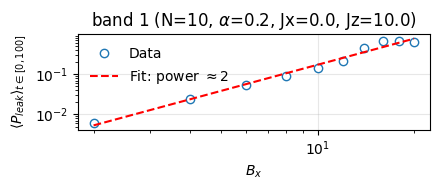

Calculated Power Law Exponent: 2.1637


In [5]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ============================================================
# INITIAL CONFIGURATION
# ============================================================
N = 10
Jz = 10.0
Jx = 0.0
alpha = 0.2
tmax = 100

# Even integer fields being varied
Bx_list = np.arange(2, 22, 2)

output_dir = "ED_Data/SectorConfinement"
avg_leakage = []

# Choose your time-averaging window
t_start = 0.0

# ============================================================
# LOAD INDIVIDUAL FILES AND COMPUTE LEAKAGE
# ============================================================
for Bx in Bx_list:
    Jz_int = int(Jz)

    # Try matching float Bx format first (e.g., Bx2.0)
    filename = f"Pleak_N{N}_Jz{Jz_int:.2f}_Jx{Jx:.1f}_Bx{Bx:.1f}_alpha{alpha}_tmax{tmax}.csv"
    full_path = os.path.join(output_dir, filename)

    # Fallback to pure integer Bx format (e.g., Bx2) if the float one doesn't exist
    if not os.path.exists(full_path):
        filename_alt = f"Pleak_N{N}_Jz{Jz_int:.2f}_Jx{Jx:.1f}_Bx{int(Bx)}_alpha{alpha}_tmax{tmax}.csv"
        full_path = os.path.join(output_dir, filename_alt)

    # If neither format exists, raise the clear error
    if not os.path.exists(full_path):
        raise FileNotFoundError(
            f"Could not find saved data file at:\n  {full_path}\n"
            f"Please verify the files in '{output_dir}' match this parameter configuration."
        )

    # Load raw time data
    df = pd.read_csv(full_path)
    t_arr = df["time"].to_numpy()
    P_t = df["Pstay"].to_numpy()

    # Slice out the transient-free window dynamically
    time_mask = t_arr >= t_start
    P_stay_avg = np.mean(P_t[time_mask])

    # Leakage = 1 - P_stay
    avg_leakage.append(1 - P_stay_avg)

# Convert to arrays
avg_leakage = np.array(avg_leakage)

# ============================================================
# POWER LAW FITTING (Fixed to use Bx_list)
# ============================================================
# Convert to log-space for fitting
log_Bx = np.log10(Bx_list)
log_leak = np.log10(avg_leakage)

# Fit a line (y = mx + c)
slope, intercept = np.polyfit(log_Bx, log_leak, 1)
fit_line = 10 ** (slope * log_Bx + intercept)

# ============================================================
# PLOT WITH FIT (Fixed labels and targets)
# ============================================================
plt.figure(figsize=(4.5, 2))
plt.plot(Bx_list, avg_leakage, "o", mfc="white", label="Data")
plt.plot(
    Bx_list,
    fit_line,
    "--",
    color="red",
    label=fr"Fit: power $\approx {slope:.0f}$",
)

plt.xscale("log")
plt.yscale("log")
plt.xlabel(r"$B_x$")
plt.ylabel(fr"$\langle P_{{leak}} \rangle_{{t \in [{int(t_start)},{tmax}]}}$")
plt.title(fr"band 1 (N={N}, $\alpha$={alpha}, Jx={Jx:.1f}, Jz={Jz:.1f})")
plt.grid(True, which="major", alpha=0.3)
plt.legend(loc="upper left", frameon=False)
plt.tight_layout()

# Save figure
os.makedirs("plt", exist_ok=True)
plt.savefig("plt/Pleak_Bx.pdf")
plt.show()

print(f"Calculated Power Law Exponent: {slope:.4f}")

In [55]:
from __future__ import annotations
import os
import numpy as np
import pandas as pd
import qutip as qt

# Parameters
Bx = 1.0
Jz = 10.0
Jx = 0.0
alpha = 0.2
tmax = 100

times = np.arange(0, 100.1, 0.1)
N_list = np.arange(8, 17, 1)

# Build directory structure
output_dir = "ED_Data/SectorConfinement"
os.makedirs(output_dir, exist_ok=True)

# Run Simulation while varying Jz
for N in N_list:
        # Z-basis state configuration ('1' means spin down/excitation)
    psi0string = "01" + "0" * (N - 2)
    target_band = psi0string.count("1")
    psi0 = product_state_from_bitstring(psi0string)
    
    H = build_H_B_Jz_Jlong(N, Bx, Jz, Jx, alpha, kac=False)
    P_t = compute_Pstay_z(H, psi0, target_band, times)

    # Prepare DataFrame storing the full time evolution for THIS Jz iteration
    df_time = pd.DataFrame({"time": times, "Pstay": P_t})

    # Include Jz dynamically in the filename alongside the other parameters
    filename = (
        f"Pleak_N{N}_Jz{Jz:.2f}_Jx{Jx:.1f}_Bx{Bx:.1f}_alpha{alpha}_tmax{tmax}.csv"
    )
    full_path = os.path.join(output_dir, filename)

    # Save to its own distinct CSV
    df_time.to_csv(full_path, index=False)
    print(f"Saved iteration Jz={Jz:.2f} to -> {full_path}")

print("\nAll simulations complete. Raw time data successfully preserved!")

Saved iteration Jz=10.00 to -> ED_Data/SectorConfinement\Pleak_N8_Jz10.00_Jx0.0_Bx1.0_alpha0.2_tmax100.csv
Saved iteration Jz=10.00 to -> ED_Data/SectorConfinement\Pleak_N9_Jz10.00_Jx0.0_Bx1.0_alpha0.2_tmax100.csv
Saved iteration Jz=10.00 to -> ED_Data/SectorConfinement\Pleak_N10_Jz10.00_Jx0.0_Bx1.0_alpha0.2_tmax100.csv
Saved iteration Jz=10.00 to -> ED_Data/SectorConfinement\Pleak_N11_Jz10.00_Jx0.0_Bx1.0_alpha0.2_tmax100.csv
Saved iteration Jz=10.00 to -> ED_Data/SectorConfinement\Pleak_N12_Jz10.00_Jx0.0_Bx1.0_alpha0.2_tmax100.csv
Saved iteration Jz=10.00 to -> ED_Data/SectorConfinement\Pleak_N13_Jz10.00_Jx0.0_Bx1.0_alpha0.2_tmax100.csv


ValueError: Function to integrate must not return a tuple.

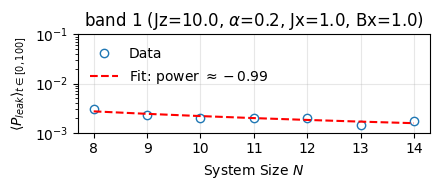

Calculated System Size (N) Scaling Exponent: -0.9900
Theoretical Expectation (2*alpha - 1): -0.60


In [9]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ============================================================
# INITIAL CONFIGURATION
# ============================================================
Bx = 1.0
Jz = 10.0
Jx = 1.0
alpha = 0.2
tmax = 100

# System sizes varied in your simulation
N_list = np.arange(8, 15, 1)

output_dir = "ED_Data/SectorConfinement"
avg_leakage = []

# Choose your time-averaging window
t_start = 0.0

# ============================================================
# LOAD INDIVIDUAL FILES AND COMPUTE LEAKAGE PER SYSTEM SIZE
# ============================================================
for N in N_list:
    # Match the simulation's Jz float naming format (Jz1.00)
    filename = (
        f"Pleak_N{N}_Jz{Jz:.2f}_Jx{Jx:.1f}_Bx{Bx:.1f}_alpha{alpha}_tmax{tmax}.csv"
    )
    full_path = os.path.join(output_dir, filename)

    # Fallback checking if Jz was written differently (e.g., Jz1)
    if not os.path.exists(full_path):
        filename_alt = f"Pleak_N{N}_Jz{int(Jz)}_Jx{Jx:.1f}_Bx{Bx:.1f}_alpha{alpha}_tmax{tmax}.csv"
        full_path = os.path.join(output_dir, filename_alt)

    if not os.path.exists(full_path):
        raise FileNotFoundError(
            f"Could not find saved data file at:\n  {full_path}\n"
            f"Please verify the files in '{output_dir}' match your configuration."
        )

    # Load raw time data
    df = pd.read_csv(full_path)
    t_arr = df["time"].to_numpy()
    P_t = df["Pstay"].to_numpy()

    # Slice out the transient-free window dynamically
    time_mask = t_arr >= t_start
    P_stay_avg = np.mean(P_t[time_mask])

    # Leakage = 1 - P_stay
    avg_leakage.append(1 - P_stay_avg)

# Convert to arrays for mathematical operations
avg_leakage = np.array(avg_leakage)
N_list = np.array(N_list, dtype=float)

# ============================================================
# POWER LAW FITTING (log(leakage) vs log(N))
# ============================================================
log_N = np.log10(N_list)
log_leak = np.log10(avg_leakage)

# Fit a line (y = mx + c)
slope, intercept = np.polyfit(log_N, log_leak, 1)
fit_line = 10 ** (slope * log_N + intercept)

# ============================================================
# PLOT WITH FIT
# ============================================================
plt.figure(figsize=(4.5, 2))
plt.plot(N_list, avg_leakage, "o", mfc="white", label="Data")
plt.plot(
    N_list,
    fit_line,
    "--",
    color="red",
    label=fr"Fit: power $\approx {slope:.2f}$",
)

plt.xscale("linear")
plt.yscale("log")
plt.ylim(1e-3,1e-1)
plt.xlabel(r"System Size $N$")
plt.ylabel(fr"$\langle P_{{leak}} \rangle_{{t \in [{int(t_start)},{tmax}]}}$")
plt.title(
    fr"band 1 (Jz={Jz:.1f}, $\alpha$={alpha}, Jx={Jx:.1f}, Bx={Bx:.1f})"
)
plt.grid(True, which="major", alpha=0.3)
plt.legend(loc="upper left", frameon=False)
plt.tight_layout()

# Save figure
os.makedirs("plt", exist_ok=True)
plt.savefig("plt/Pleak_N.pdf")
plt.show()

print(f"Calculated System Size (N) Scaling Exponent: {slope:.4f}")
print(f"Theoretical Expectation (2*alpha - 1): {2 * alpha - 1:.2f}")

# Fidelity/Return Probability

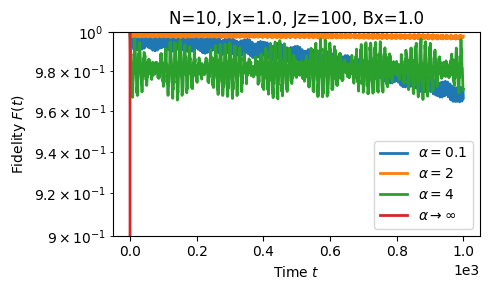

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# parameters
N = 10
Jz = 100
Jx = 1.0
Bx = 1.0

alphas = [0.1, 2, 4, 100] #, 

tmax=1000
times = np.linspace(0, tmax, int(tmax))

# initial state (mostly + in x basis)
psi0string="10"+"1"*(N-2)
psi0 = product_state_from_bitstring(psi0string)

# diagonalize + compute fidelities
F_list = []

for alpha in alphas:
    H = build_H_B_Jz_Jlong(N=N, Bx=Bx, Jz=Jz, Jx=Jx, alpha=alpha, kac=False)

    evals, evecs = diagonalize(H)

    coeffs = np.array([v.overlap(psi0) for v in evecs])

    F = fidelity_from_spectrum(evals, coeffs, times)

    F_list.append(F)

# plotting
plt.figure(figsize=(5,3))

for alpha, F in zip(alphas, F_list):
    label = r"$\alpha \to \infty$" if alpha >= 100 else rf"$\alpha={alpha}$"
    plt.semilogy(times, F, lw=2, label=label)

plt.xlabel("Time $t$")
plt.ylabel(r"Fidelity $F(t)$")
plt.title(f"N={N}, Jx={Jx}, Jz={Jz}, Bx={Bx}")
plt.legend(frameon=True)
plt.ylim(9e-1, 1)
plt.ticklabel_format(style='sci', axis='x', scilimits=(0, 0))
plt.tight_layout()
plt.savefig("plt/StateFidelity(t).pdf")
plt.show()

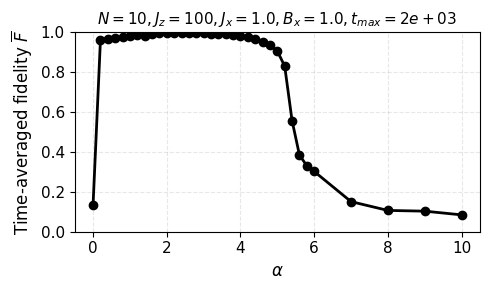

In [10]:
plt.figure(figsize=(5, 3))

plt.plot(alphas, F_avg, marker='o', lw=2, color='black')

plt.ylim(0, 1)

plt.xlabel(r"$\alpha$", fontsize=12)
plt.ylabel(r"Time-averaged fidelity $\overline{F}$", fontsize=12)

plt.title(rf"$N={N}, J_z={Jz}, J_x={Jx}, B_x={Bx}, t_{{max}}={tmax:.0e}$", fontsize=11)

plt.grid(True, alpha=0.3, linestyle='--')

plt.tick_params(axis='both', which='major', labelsize=11)

plt.tight_layout()
plt.savefig("plt/AvgStateFidelity(alpha).pdf")
plt.show()

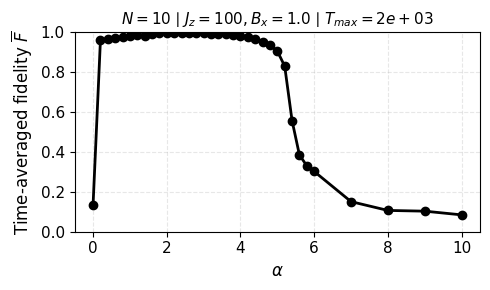

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# parameters
N = 10
Jz = 100
Jx = 1.0
Bx = 1.0

alphas = [i/5 for i in range(31)] + [7,8,9,10]
tmax=2000

times = np.linspace(0, tmax, tmax*10)

# initial state
psi0string="10"+"1"*(N-2)
psi0 = product_state_from_bitstring(psi0string)

F_avg = []

for alpha in alphas:
    H = build_H_B_Jz_Jlong(N=N, Bx=Bx, Jz=Jz, Jx=Jx, alpha=alpha, kac=False)

    evals, evecs = diagonalize(H)

    coeffs = np.array([v.overlap(psi0) for v in evecs])

    F = fidelity_from_spectrum(evals, coeffs, times)

    # ---- time average fidelity ----
    F_avg.append(np.mean(F))

plt.figure(figsize=(5, 3))

plt.plot(alphas, F_avg, marker='o', lw=2, color='black')

plt.ylim(0, 1)

plt.xlabel(r"$\alpha$", fontsize=12)
plt.ylabel(r"Time-averaged fidelity $\overline{F}$", fontsize=12)

plt.title(rf"$N={N} \mid J_z={Jz}, B_x={Bx} \mid T_{{max}}={tmax:.0e}$", fontsize=11)

plt.grid(True, alpha=0.3, linestyle='--')

plt.tick_params(axis='both', which='major', labelsize=11)

plt.tight_layout()
plt.savefig("plt/AvgStateFidelity(alpha).pdf")
plt.show()

# Check Ergodicity

## Our Hamiltonian

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations
from scipy.linalg import eigh


# ============================================================
# Basis: fixed n_up sector (generalizes half-filled)
# ============================================================

def fixed_excitation_basis(L, n_up):
    basis = []
    for ups in combinations(range(L), n_up):
        state = [0] * L
        for i in ups:
            state[i] = 1
        basis.append(tuple(state))
    return basis

def basis_index(basis):
    return {state: i for i, state in enumerate(basis)}


# ============================================================
# H0 + V in the fixed-n_up sector
#
# H0 = sum_{i<j} Jz/|i-j|^alpha * sigma_i^z sigma_j^z   (reflection symmetric)
# V  ~ Jx * flip-flop (nearest-neighbor)                (reflection symmetric)
# disorder: sum_i h_i sigma_i^z  -- SYMMETRIZED so [H,P]=0 holds exactly
# ============================================================

def build_H_longrange_projected(L, n_up, Jz, alpha, Jx, h=None):

    basis = fixed_excitation_basis(L, n_up)
    index = basis_index(basis)
    dim = len(basis)
    H = np.zeros((dim, dim), dtype=float)

    for n, state in enumerate(basis):

        diag = 0.0
        for i in range(L):
            si = 1 if state[i] == 1 else -1
            if h is not None:
                diag += h[i] * si
            for j in range(i + 1, L):
                sj = 1 if state[j] == 1 else -1
                diag += Jz / (abs(i - j) ** alpha) * si * sj
        H[n, n] = diag

        for i in range(L - 1):
            if state[i] != state[i + 1]:
                new_state = list(state)
                new_state[i], new_state[i + 1] = new_state[i + 1], new_state[i]
                new_state = tuple(new_state)
                m = index[new_state]
                H[m, n] += Jx

    return H, basis


# ============================================================
# Reflection symmetry: build the even/odd change-of-basis
# ============================================================

def reflection_blocks(basis):
    """
    Partition `basis` into P=+1 (even) and P=-1 (odd) combinations.

    Returns
    -------
    U        : (dim x dim) orthogonal change-of-basis matrix,
               columns = [even combos, odd combos]
    n_even   : number of even basis vectors (first n_even columns of U)
    """

    L = len(basis[0])
    index = basis_index(basis)
    dim = len(basis)

    visited = np.zeros(dim, dtype=bool)

    even_vecs = []
    odd_vecs = []

    for n, state in enumerate(basis):

        if visited[n]:
            continue

        mirrored = state[::-1]
        m = index[mirrored]

        if m == n:
            # self-mirrored (palindromic) state -> even only
            v = np.zeros(dim)
            v[n] = 1.0
            even_vecs.append(v)
            visited[n] = True
        else:
            v_even = np.zeros(dim)
            v_even[n] = 1/np.sqrt(2)
            v_even[m] = 1/np.sqrt(2)
            even_vecs.append(v_even)

            v_odd = np.zeros(dim)
            v_odd[n] = 1/np.sqrt(2)
            v_odd[m] = -1/np.sqrt(2)
            odd_vecs.append(v_odd)

            visited[n] = True
            visited[m] = True

    n_even = len(even_vecs)
    U = np.array(even_vecs + odd_vecs).T   # columns are basis vectors

    return U, n_even


def block_diagonalize_by_parity(H, basis):

    U, n_even = reflection_blocks(basis)

    H_rot = U.T @ H @ U   # exactly block-diagonal if [H,P]=0

    H_even = H_rot[:n_even, :n_even]
    H_odd  = H_rot[n_even:, n_even:]

    # sanity check: off-diagonal blocks should be ~0
    off_block_norm = np.max(np.abs(H_rot[:n_even, n_even:]))

    return H_even, H_odd, U, n_even, off_block_norm


# ============================================================
# Diagonalization / statistics helpers
# ============================================================

def diagonalize(H):
    return eigh(H)

def middle_spectrum(evals, evecs, frac=1.0):
    N = len(evals)
    start = int(N * (0.5 - frac / 2))
    end = int(N * (0.5 + frac / 2))
    return evals[start:end], evecs[:, start:end]

def level_spacing_ratio(evals):
    evals = np.sort(evals)
    spacings = np.diff(evals)
    if len(spacings) < 2:
        return np.nan
    r = [min(spacings[i], spacings[i+1]) / max(spacings[i], spacings[i+1])
         for i in range(len(spacings) - 1)]
    return np.mean(r)

def compute_IPR(evecs):
    return np.array([np.sum(np.abs(evecs[:, n]) ** 4) for n in range(evecs.shape[1])])


# ============================================================
# Left-half entanglement entropy (real ergodicity/localization probe)
# ============================================================

def entanglement_entropy(psi, basis, cut):
    """
    psi   : state vector in the ORIGINAL occupation basis (length = dim)
    basis : list of L-site tuples matching psi's ordering
    cut   : number of sites in the "left half" (0..cut-1)

    Builds rho_left = Tr_right |psi><psi| via an SVD of the
    amplitude matrix indexed by (left_config, right_config),
    and returns the von Neumann entropy of its eigenvalues.
    """

    from collections import defaultdict

    amp_map = defaultdict(dict)

    for coeff, state in zip(psi, basis):
        left = state[:cut]
        right = state[cut:]
        amp_map[left][right] = coeff

    lefts = list(amp_map.keys())
    rights = sorted(set(r for d in amp_map.values() for r in d))
    right_index = {r: j for j, r in enumerate(rights)}

    M = np.zeros((len(lefts), len(rights)))
    for i, l in enumerate(lefts):
        for r, val in amp_map[l].items():
            M[i, right_index[r]] = val

    svals = np.linalg.svd(M, compute_uv=False)
    p = svals ** 2
    p = p[p > 1e-14]
    p = p / p.sum()   # guard against normalization drift

    return -np.sum(p * np.log(p))


def reconstruct_full_eigvecs(U_block, evecs_block, n_even, block="even"):
    """
    Map eigenvectors of the even/odd block back to the ORIGINAL
    site-occupation basis, using the same U from block_diagonalize_by_parity.
    """
    if block == "even":
        U_sub = U_block[:, :n_even]
    else:
        U_sub = U_block[:, n_even:]

    return U_sub @ evecs_block   # (dim x n_states), original basis


# ============================================================
# Single realization: n_up, reflection-projected, both diagnostics
# ============================================================

def analyze_realization(L, n_up, W, Jz=1.0, alpha=1.5, Jx=0.1, frac=1.0, cut=None):

    if cut is None:
        cut = L // 2

    # --- symmetrized disorder: h_i = h_{L-1-i}, so [H,P]=0 exactly ---
    h_half = np.random.uniform(-W, W, (L + 1) // 2)
    h = np.array([h_half[min(i, L - 1 - i)] for i in range(L)])

    H, basis = build_H_longrange_projected(L, n_up, Jz=Jz, alpha=alpha, Jx=Jx, h=h)

    H_even, H_odd, U, n_even, off_norm = block_diagonalize_by_parity(H, basis)

    r_vals, ipr_vals, S_vals = [], [], []

    for H_block, is_even in [(H_even, True), (H_odd, False)]:

        if H_block.shape[0] < 3:
            continue

        evals, evecs = diagonalize(H_block)
        evals_mid, evecs_mid = middle_spectrum(evals, evecs, frac)

        r = level_spacing_ratio(evals_mid)
        ipr = np.mean(compute_IPR(evecs_mid))

        # reconstruct a handful of mid-spectrum eigenstates in the
        # original basis to compute left-half entanglement entropy
        psi_full = reconstruct_full_eigvecs(
            U, evecs_mid, n_even, block="even" if is_even else "odd"
        )

        S_block = [entanglement_entropy(psi_full[:, k], basis, cut)
                   for k in range(psi_full.shape[1])]

        r_vals.append(r)
        ipr_vals.append(ipr)
        S_vals.extend(S_block)

    return (
        np.nanmean(r_vals),
        np.mean(ipr_vals),
        np.mean(S_vals),
        off_norm,
    )


def disorder_average(L, n_up, W, realizations=50, Jz=1.0, alpha=1.5, Jx=0.1, frac=1, cut=None):

    r_values, ipr_values, S_values, off_norms = [], [], [], []

    for _ in range(realizations):
        r, ipr, S, off_norm = analyze_realization(
            L=L, n_up=n_up, W=W, Jz=Jz, alpha=alpha, Jx=Jx, frac=frac, cut=cut
        )
        r_values.append(r)
        ipr_values.append(ipr)
        S_values.append(S)
        off_norms.append(off_norm)

    return (
        np.nanmean(r_values), np.nanstd(r_values),
        np.mean(ipr_values), np.std(ipr_values),
        np.mean(S_values), np.std(S_values),
        np.max(off_norms),   # should be ~0 if reflection symmetry held exactly
    )


### $J_z$ sweep

In [2]:
import csv
import os
import numpy as np
from itertools import combinations

# ============================================================
# Jz sweep at fixed alpha = 0.5, multiple n_up sectors
# Results written directly to CSV, one row per (n_up, Jz)
# ============================================================

L = 11
n_up_values = [1, 2, 3, L // 2]   # sectors to compare
alpha = 0.5                       # fixed
Jx = 1.0

# Generates [0.0, 0.4, 0.6, ..., 4.0] (skipping 0.2)
Wlist = [i / 10 for i in range(0, 41, 2) if i!=2]

output_dir = "MBL"
os.makedirs(output_dir, exist_ok=True)

for W in Wlist:
        
    Jz_values = np.linspace(0.0, 20.0, 51)   # adjust range as needed
    output_file = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W{W}.csv")

    fieldnames = ["n_up", "Jz", "alpha", "Jx", "W", "L",
                "r_mean", "r_std", "ipr_mean", "ipr_std",
                "S_mean", "S_std", "off_norm"]

    with open(output_file, "w", newline="") as f:

        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()

        for n_up in n_up_values:
            for Jz in Jz_values:

                r_mean, r_std, ipr_mean, ipr_std, S_mean, S_std, off_norm = disorder_average(
                    L=L, n_up=n_up, W=W, realizations=120, Jz=Jz, alpha=alpha, Jx=Jx, frac=1
                )

                row = {
                    "n_up": n_up, "Jz": Jz, "alpha": alpha, "Jx": Jx, "W": W, "L": L,
                    "r_mean": r_mean, "r_std": r_std,
                    "ipr_mean": ipr_mean, "ipr_std": ipr_std,
                    "S_mean": S_mean, "S_std": S_std,
                    "off_norm": off_norm,
                }

                writer.writerow(row)
                f.flush()

                print(f"n_up={n_up}  Jz={Jz:.2f}  <r>={r_mean:.4f}  IPR={ipr_mean:.4f}  "
                    f"S_ent={S_mean:.4f}  max off-block norm={off_norm:.2e}")

# ------------------------------------------------------------
# Reference: Page-like entropy estimate, per n_up
# (Moved outside W loop since it only depends on L and n_up)
# ------------------------------------------------------------
cut = L // 2
page_file = os.path.join(output_dir, f"page_estimates_L{L}.csv")

with open(page_file, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=["n_up", "S_max_estimate"])
    writer.writeheader()

    for n_up in n_up_values:
        S_max = np.log(min(
            sum(1 for _ in combinations(range(cut), min(n_up, cut))),
            sum(1 for _ in combinations(range(L - cut), min(n_up, L - cut)))
        ) + 1)
        writer.writerow({"n_up": n_up, "S_max_estimate": S_max})

print(f"\nDone. Results in MBL directory, Page estimates in {page_file}")

NameError: name 'disorder_average' is not defined

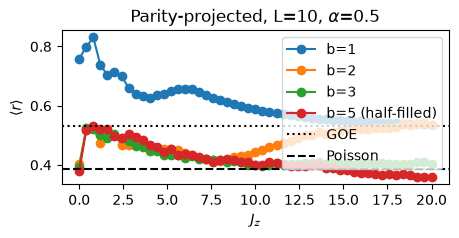

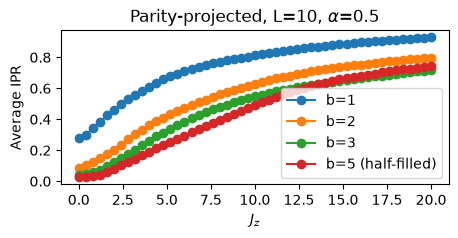

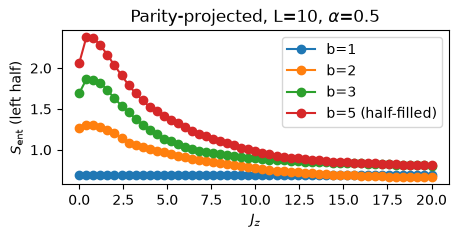

In [ ]:
import pandas as pd
import os

# ------------------------------------------------------------
# Load data
# ------------------------------------------------------------

output_dir = "MBL"

L = 10
alpha = 0.5
W = 0.2

sweep_file = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W{W}.csv")
page_file = os.path.join(output_dir, f"page_estimates_L{L}.csv")

df = pd.read_csv(sweep_file)
page = pd.read_csv(page_file).set_index("n_up")["S_max_estimate"]

# n_up_values = sorted(df["n_up"].unique())

n_up_values =1
# ------------------------------------------------------------
# Plot <r> for all sectors together
# ------------------------------------------------------------

plt.figure(figsize=(5, 2))

for n_up in n_up_values:
    sub = df[df["n_up"] == n_up].sort_values("Jz")
    label = f"b={n_up}" + (" (half-filled)" if n_up == L // 2 else "")
    plt.plot(sub["Jz"], sub["r_mean"], marker="o", label=label)

plt.axhline(0.5307, linestyle=":", color="k", label="GOE")
plt.axhline(0.3863, linestyle="--", color="k", label="Poisson")
plt.xlabel(r"$J_z$")
plt.ylabel(r"$\langle r\rangle$")
plt.title(rf"Parity-projected, L={L}, $\alpha$={alpha}")
plt.legend()
plt.show()


# ------------------------------------------------------------
# Plot IPR for all sectors together
# ------------------------------------------------------------

plt.figure(figsize=(5, 2))

for n_up in n_up_values:
    sub = df[df["n_up"] == n_up].sort_values("Jz")
    label = f"b={n_up}" + (" (half-filled)" if n_up == L // 2 else "")
    plt.plot(sub["Jz"], sub["ipr_mean"], marker="o", label=label)

plt.xlabel(r"$J_z$")
plt.ylabel("Average IPR")
plt.title(rf"Parity-projected, L={L}, $\alpha$={alpha}")
plt.legend()
plt.show()


# ------------------------------------------------------------
# Plot entanglement entropy for all sectors together
# ------------------------------------------------------------

plt.figure(figsize=(5, 2))

for n_up in n_up_values:
    sub = df[df["n_up"] == n_up].sort_values("Jz")
    label = f"b={n_up}" + (" (half-filled)" if n_up == L // 2 else "")
    line, = plt.plot(sub["Jz"], sub["S_mean"], marker="o", label=label)
    # matching-colored dashed reference line for this sector's Page estimate
    # plt.axhline(page[n_up], linestyle=":", color=line.get_color(), alpha=0.5)

plt.xlabel(r"$J_z$")
plt.ylabel(r"$S_{\rm ent}$ (left half)")
plt.title(rf"Parity-projected, L={L}, $\alpha$={alpha}")  # (dotted = Page estimate per sector)
plt.legend()
plt.show()

In [1]:
import os
import glob
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. Configuration & Data Loading
# ============================================================
output_dir = "MBL"
L = 11
alpha = 0.5
n_up_target = L // 2  # Focus on half-filling (or set to 1, 2, 3)

# Search for all W files matching L and alpha
file_pattern = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W*.csv")
files = glob.glob(file_pattern)

dfs = []
for fname in files:
    # Extract W value directly from file name to ensure precise float parsing
    match = re.search(r"W([0-9.]+)\.csv", fname)
    if match:
        df_temp = pd.read_csv(fname)
        dfs.append(df_temp)

if not dfs:
    raise FileNotFoundError(f"No sweep CSV files found matching {file_pattern}")

# Combine all W data into a single DataFrame
full_df = pd.concat(dfs, ignore_index=True)

# Filter for the target symmetry sector
sector_df = full_df[full_df["n_up"] == n_up_target]

# ============================================================
# 2. Pivot into 2D Grids (Rows = Jz, Cols = W)
# ============================================================
grid_r = sector_df.pivot(index="Jz", columns="W", values="r_mean").sort_index(ascending=True)
grid_ipr = sector_df.pivot(index="Jz", columns="W", values="ipr_mean").sort_index(ascending=True)
grid_S = sector_df.pivot(index="Jz", columns="W", values="S_mean").sort_index(ascending=True)

# Calculate Participation Ratio PR = 1 / IPR and take log2(PR)
grid_log2_PR = np.log2(1.0 / grid_ipr)

W_vals = grid_r.columns.values
Jz_vals = grid_r.index.values

# ============================================================
# 3. Plot Phase Diagrams (Heatmaps)
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

# --- (A) r-index Heatmap ---
im0 = axes[0].pcolormesh(
    W_vals, Jz_vals, grid_r.values, 
    cmap="viridis", vmin=0.3863, vmax=0.5307, shading="nearest"
)
axes[0].set_title(r"(A) Level Spacing Ratio $\langle r \rangle$", fontsize=12)
axes[0].set_xlabel(r"Disorder Strength $W$", fontsize=11)
axes[0].set_ylabel(r"Coupling / Field $J_z$", fontsize=11)
cbar0 = fig.colorbar(im0, ax=axes[0])
cbar0.set_label(r"$\langle r \rangle$", fontsize=10)

# Optional phase boundary contour line at r ≈ 0.46
# axes[0].contour(
#     W_vals, Jz_vals, grid_r.values, 
#     levels=[0.46], colors="r", linewidths=1.5
# )

# --- (B) log2(PR) Heatmap ---
im1 = axes[1].pcolormesh(
    W_vals, Jz_vals, grid_log2_PR.values, 
    cmap="viridis", shading="nearest"
)
axes[1].set_title(r"(B) Participation Ratio $\log_2(\text{PR})$", fontsize=12)
axes[1].set_xlabel(r"Disorder Strength $W$", fontsize=11)
cbar1 = fig.colorbar(im1, ax=axes[1])
cbar1.set_label(r"$\log_2(\text{PR})$", fontsize=10)

# axes[1].contour(
#     W_vals, Jz_vals, grid_r.values, 
#     levels=[0.46], colors="r", linewidths=1.5
# )

# --- (C) Entanglement Entropy Heatmap ---
im2 = axes[2].pcolormesh(
    W_vals, Jz_vals, grid_S.values, 
    cmap="magma", shading="nearest"
)
axes[2].set_title(r"(C) Entanglement Entropy $S_{\rm ent}$", fontsize=12)
axes[2].set_xlabel(r"Disorder Strength $W$", fontsize=11)
cbar2 = fig.colorbar(im2, ax=axes[2])
cbar2.set_label(r"$S_{\rm ent}$", fontsize=10)

fig.suptitle(f"Phase Diagram ($L={L}$, $\\alpha={alpha}$, $b={n_up_target}$)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

TypeError: loop of ufunc does not support argument 0 of type float which has no callable log2 method

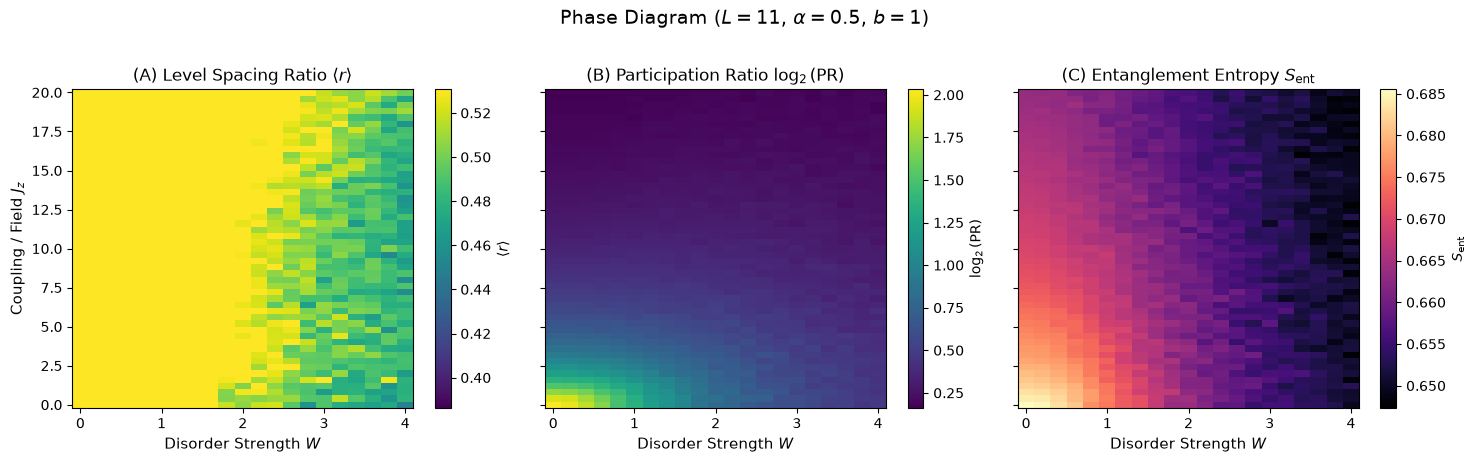

In [22]:
import os
import glob
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. Configuration & Data Loading
# ============================================================
output_dir = "MBL"
L = 11
alpha = 0.5
n_up_target = 1  # Focus on half-filling (or set to 1, 2, 3)

# Search for all W files matching L and alpha
file_pattern = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W*.csv")
files = glob.glob(file_pattern)

dfs = []
for fname in files:
    # Extract W value directly from file name to ensure precise float parsing
    match = re.search(r"W([0-9.]+)\.csv", fname)
    if match:
        df_temp = pd.read_csv(fname)
        dfs.append(df_temp)

if not dfs:
    raise FileNotFoundError(f"No sweep CSV files found matching {file_pattern}")

# Combine all W data into a single DataFrame
full_df = pd.concat(dfs, ignore_index=True)

# Filter for the target symmetry sector
sector_df = full_df[full_df["n_up"] == n_up_target]

# ============================================================
# 2. Pivot into 2D Grids (Rows = Jz, Cols = W)
# ============================================================
grid_r = sector_df.pivot(index="Jz", columns="W", values="r_mean").sort_index(ascending=True)
grid_ipr = sector_df.pivot(index="Jz", columns="W", values="ipr_mean").sort_index(ascending=True)
grid_S = sector_df.pivot(index="Jz", columns="W", values="S_mean").sort_index(ascending=True)

# Calculate Participation Ratio PR = 1 / IPR and take log2(PR)
grid_log2_PR = np.log2(1.0 / grid_ipr)

W_vals = grid_r.columns.values
Jz_vals = grid_r.index.values

# ============================================================
# 3. Plot Phase Diagrams (Heatmaps)
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

# --- (A) r-index Heatmap ---
im0 = axes[0].pcolormesh(
    W_vals, Jz_vals, grid_r.values, 
    cmap="viridis", vmin=0.3863, vmax=0.5307, shading="nearest"
)
axes[0].set_title(r"(A) Level Spacing Ratio $\langle r \rangle$", fontsize=12)
axes[0].set_xlabel(r"Disorder Strength $W$", fontsize=11)
axes[0].set_ylabel(r"Coupling / Field $J_z$", fontsize=11)
cbar0 = fig.colorbar(im0, ax=axes[0])
cbar0.set_label(r"$\langle r \rangle$", fontsize=10)

# Optional phase boundary contour line at r ≈ 0.46
# axes[0].contour(
#     W_vals, Jz_vals, grid_r.values, 
#     levels=[0.46], colors="r", linewidths=1.5
# )

# --- (B) log2(PR) Heatmap ---
im1 = axes[1].pcolormesh(
    W_vals, Jz_vals, grid_log2_PR.values, 
    cmap="viridis", shading="nearest"
)
axes[1].set_title(r"(B) Participation Ratio $\log_2(\text{PR})$", fontsize=12)
axes[1].set_xlabel(r"Disorder Strength $W$", fontsize=11)
cbar1 = fig.colorbar(im1, ax=axes[1])
cbar1.set_label(r"$\log_2(\text{PR})$", fontsize=10)

# axes[1].contour(
#     W_vals, Jz_vals, grid_r.values, 
#     levels=[0.46], colors="r", linewidths=1.5
# )

# --- (C) Entanglement Entropy Heatmap ---
im2 = axes[2].pcolormesh(
    W_vals, Jz_vals, grid_S.values, 
    cmap="magma", shading="nearest"
)
axes[2].set_title(r"(C) Entanglement Entropy $S_{\rm ent}$", fontsize=12)
axes[2].set_xlabel(r"Disorder Strength $W$", fontsize=11)
cbar2 = fig.colorbar(im2, ax=axes[2])
cbar2.set_label(r"$S_{\rm ent}$", fontsize=10)

fig.suptitle(f"Phase Diagram ($L={L}$, $\\alpha={alpha}$, $b={n_up_target}$)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

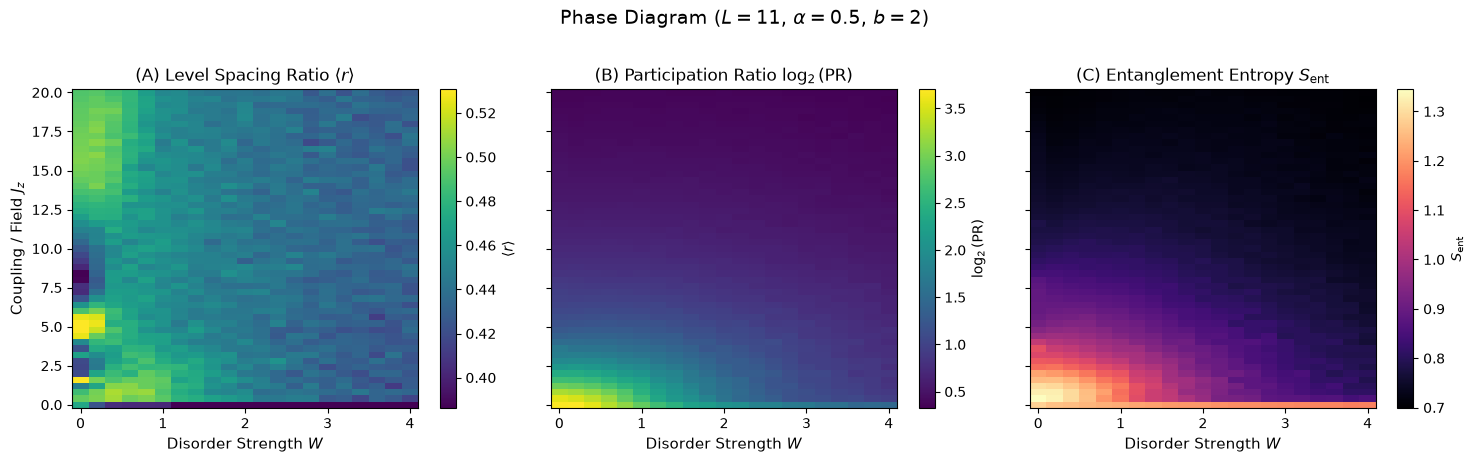

In [23]:
import os
import glob
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. Configuration & Data Loading
# ============================================================
output_dir = "MBL"
L = 11
alpha = 0.5
n_up_target = 2  # Focus on half-filling (or set to 1, 2, 3)

# Search for all W files matching L and alpha
file_pattern = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W*.csv")
files = glob.glob(file_pattern)

dfs = []
for fname in files:
    # Extract W value directly from file name to ensure precise float parsing
    match = re.search(r"W([0-9.]+)\.csv", fname)
    if match:
        df_temp = pd.read_csv(fname)
        dfs.append(df_temp)

if not dfs:
    raise FileNotFoundError(f"No sweep CSV files found matching {file_pattern}")

# Combine all W data into a single DataFrame
full_df = pd.concat(dfs, ignore_index=True)

# Filter for the target symmetry sector
sector_df = full_df[full_df["n_up"] == n_up_target]

# ============================================================
# 2. Pivot into 2D Grids (Rows = Jz, Cols = W)
# ============================================================
grid_r = sector_df.pivot(index="Jz", columns="W", values="r_mean").sort_index(ascending=True)
grid_ipr = sector_df.pivot(index="Jz", columns="W", values="ipr_mean").sort_index(ascending=True)
grid_S = sector_df.pivot(index="Jz", columns="W", values="S_mean").sort_index(ascending=True)

# Calculate Participation Ratio PR = 1 / IPR and take log2(PR)
grid_log2_PR = np.log2(1.0 / grid_ipr)

W_vals = grid_r.columns.values
Jz_vals = grid_r.index.values

# ============================================================
# 3. Plot Phase Diagrams (Heatmaps)
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

# --- (A) r-index Heatmap ---
im0 = axes[0].pcolormesh(
    W_vals, Jz_vals, grid_r.values, 
    cmap="viridis", vmin=0.3863, vmax=0.5307, shading="nearest"
)
axes[0].set_title(r"(A) Level Spacing Ratio $\langle r \rangle$", fontsize=12)
axes[0].set_xlabel(r"Disorder Strength $W$", fontsize=11)
axes[0].set_ylabel(r"Coupling / Field $J_z$", fontsize=11)
cbar0 = fig.colorbar(im0, ax=axes[0])
cbar0.set_label(r"$\langle r \rangle$", fontsize=10)

# Optional phase boundary contour line at r ≈ 0.46
# axes[0].contour(
#     W_vals, Jz_vals, grid_r.values, 
#     levels=[0.46], colors="r", linewidths=1.5
# )

# --- (B) log2(PR) Heatmap ---
im1 = axes[1].pcolormesh(
    W_vals, Jz_vals, grid_log2_PR.values, 
    cmap="viridis", shading="nearest"
)
axes[1].set_title(r"(B) Participation Ratio $\log_2(\text{PR})$", fontsize=12)
axes[1].set_xlabel(r"Disorder Strength $W$", fontsize=11)
cbar1 = fig.colorbar(im1, ax=axes[1])
cbar1.set_label(r"$\log_2(\text{PR})$", fontsize=10)

# axes[1].contour(
#     W_vals, Jz_vals, grid_r.values, 
#     levels=[0.46], colors="r", linewidths=1.5
# )

# --- (C) Entanglement Entropy Heatmap ---
im2 = axes[2].pcolormesh(
    W_vals, Jz_vals, grid_S.values, 
    cmap="magma", shading="nearest"
)
axes[2].set_title(r"(C) Entanglement Entropy $S_{\rm ent}$", fontsize=12)
axes[2].set_xlabel(r"Disorder Strength $W$", fontsize=11)
cbar2 = fig.colorbar(im2, ax=axes[2])
cbar2.set_label(r"$S_{\rm ent}$", fontsize=10)

fig.suptitle(f"Phase Diagram ($L={L}$, $\\alpha={alpha}$, $b={n_up_target}$)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

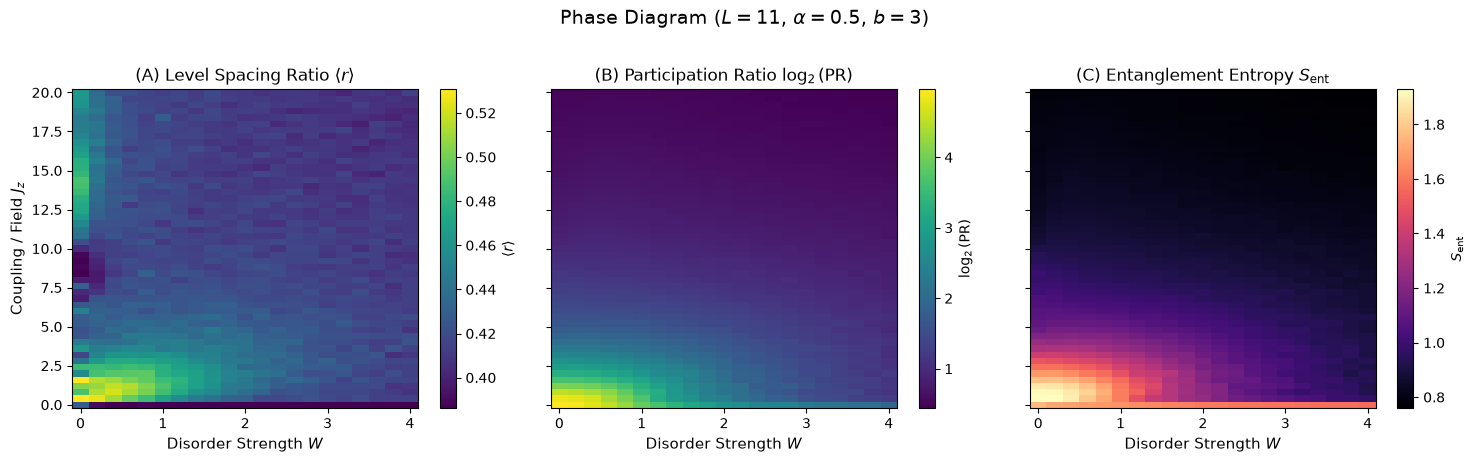

In [24]:
import os
import glob
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. Configuration & Data Loading
# ============================================================
output_dir = "MBL"
L = 11
alpha = 0.5
n_up_target = 3  # Focus on half-filling (or set to 1, 2, 3)

# Search for all W files matching L and alpha
file_pattern = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W*.csv")
files = glob.glob(file_pattern)

dfs = []
for fname in files:
    # Extract W value directly from file name to ensure precise float parsing
    match = re.search(r"W([0-9.]+)\.csv", fname)
    if match:
        df_temp = pd.read_csv(fname)
        dfs.append(df_temp)

if not dfs:
    raise FileNotFoundError(f"No sweep CSV files found matching {file_pattern}")

# Combine all W data into a single DataFrame
full_df = pd.concat(dfs, ignore_index=True)

# Filter for the target symmetry sector
sector_df = full_df[full_df["n_up"] == n_up_target]

# ============================================================
# 2. Pivot into 2D Grids (Rows = Jz, Cols = W)
# ============================================================
grid_r = sector_df.pivot(index="Jz", columns="W", values="r_mean").sort_index(ascending=True)
grid_ipr = sector_df.pivot(index="Jz", columns="W", values="ipr_mean").sort_index(ascending=True)
grid_S = sector_df.pivot(index="Jz", columns="W", values="S_mean").sort_index(ascending=True)

# Calculate Participation Ratio PR = 1 / IPR and take log2(PR)
grid_log2_PR = np.log2(1.0 / grid_ipr)

W_vals = grid_r.columns.values
Jz_vals = grid_r.index.values

# ============================================================
# 3. Plot Phase Diagrams (Heatmaps)
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

# --- (A) r-index Heatmap ---
im0 = axes[0].pcolormesh(
    W_vals, Jz_vals, grid_r.values, 
    cmap="viridis", vmin=0.3863, vmax=0.5307, shading="nearest"
)
axes[0].set_title(r"(A) Level Spacing Ratio $\langle r \rangle$", fontsize=12)
axes[0].set_xlabel(r"Disorder Strength $W$", fontsize=11)
axes[0].set_ylabel(r"Coupling / Field $J_z$", fontsize=11)
cbar0 = fig.colorbar(im0, ax=axes[0])
cbar0.set_label(r"$\langle r \rangle$", fontsize=10)

# Optional phase boundary contour line at r ≈ 0.46
# axes[0].contour(
#     W_vals, Jz_vals, grid_r.values, 
#     levels=[0.46], colors="r", linewidths=1.5
# )

# --- (B) log2(PR) Heatmap ---
im1 = axes[1].pcolormesh(
    W_vals, Jz_vals, grid_log2_PR.values, 
    cmap="viridis", shading="nearest"
)
axes[1].set_title(r"(B) Participation Ratio $\log_2(\text{PR})$", fontsize=12)
axes[1].set_xlabel(r"Disorder Strength $W$", fontsize=11)
cbar1 = fig.colorbar(im1, ax=axes[1])
cbar1.set_label(r"$\log_2(\text{PR})$", fontsize=10)

# axes[1].contour(
#     W_vals, Jz_vals, grid_r.values, 
#     levels=[0.46], colors="r", linewidths=1.5
# )

# --- (C) Entanglement Entropy Heatmap ---
im2 = axes[2].pcolormesh(
    W_vals, Jz_vals, grid_S.values, 
    cmap="magma", shading="nearest"
)
axes[2].set_title(r"(C) Entanglement Entropy $S_{\rm ent}$", fontsize=12)
axes[2].set_xlabel(r"Disorder Strength $W$", fontsize=11)
cbar2 = fig.colorbar(im2, ax=axes[2])
cbar2.set_label(r"$S_{\rm ent}$", fontsize=10)

fig.suptitle(f"Phase Diagram ($L={L}$, $\\alpha={alpha}$, $b={n_up_target}$)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

### N Sweep

In [8]:
import csv
import os
import numpy as np
from itertools import combinations

# ============================================================
# Jz sweep across multiple system sizes L
# Fixed parameters: alpha = 0.5, W = 0.2, Jx = 1.0
# ============================================================

# Define list of system sizes L to sweep over
L_list = [16]  

alpha = 0.5     # fixed long-range exponent
W = 0.2         # fixed disorder strength
Jx = 1.0        # fixed transverse coupling
Jz_values = np.linspace(0.0, 20.0, 11)  # adjust range/points as needed

output_dir = "MBL"
os.makedirs(output_dir, exist_ok=True)

fieldnames = ["n_up", "Jz", "alpha", "Jx", "W", "L",
              "r_mean", "r_std", "ipr_mean", "ipr_std",
              "S_mean", "S_std", "off_norm"]

for L in L_list:
    # Set sector range per L (e.g., 1, 2, 3, and half-filling)
    n_up_values = sorted(list(set([L // 2]))) #1, 2, 3,
    
    output_file = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W{W}.csv")
    
    print(f"\n--- Starting sweep for L = {L} (W = {W}, alpha = {alpha}) ---")

    with open(output_file, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()

        for n_up in n_up_values:
            for Jz in Jz_values:

                r_mean, r_std, ipr_mean, ipr_std, S_mean, S_std, off_norm = disorder_average(
                    L=L, n_up=n_up, W=W, realizations=10, Jz=Jz, alpha=alpha, Jx=Jx, frac=1
                )

                row = {
                    "n_up": n_up, "Jz": Jz, "alpha": alpha, "Jx": Jx, "W": W, "L": L,
                    "r_mean": r_mean, "r_std": r_std,
                    "ipr_mean": ipr_mean, "ipr_std": ipr_std,
                    "S_mean": S_mean, "S_std": S_std,
                    "off_norm": off_norm,
                }

                writer.writerow(row)
                f.flush()

                print(f"[L={L}] n_up={n_up}  Jz={Jz:.2f}  <r>={r_mean:.4f}  "
                      f"IPR={ipr_mean:.4f}  S_ent={S_mean:.4f}  max off-block norm={off_norm:.2e}")

    # Save Page estimates specific to this L
    cut = L // 2
    page_file = os.path.join(output_dir, f"page_estimates_L{L}.csv")

    with open(page_file, "w", newline="") as f:
        writer_page = csv.DictWriter(f, fieldnames=["n_up", "S_max_estimate"])
        writer_page.writeheader()

        for n_up in n_up_values:
            S_max = np.log(min(
                sum(1 for _ in combinations(range(cut), min(n_up, cut))),
                sum(1 for _ in combinations(range(L - cut), min(n_up, L - cut)))
            ) + 1)
            writer_page.writerow({"n_up": n_up, "S_max_estimate": S_max})

print(f"\nSweep complete. All results written to '{output_dir}/'")


--- Starting sweep for L = 16 (W = 0.2, alpha = 0.5) ---
[L=16] n_up=8  Jz=0.00  <r>=0.3926  IPR=0.0009  S_ent=3.1565  max off-block norm=3.33e-16
[L=16] n_up=8  Jz=2.00  <r>=0.5192  IPR=0.0096  S_ent=3.9361  max off-block norm=1.42e-14
[L=16] n_up=8  Jz=4.00  <r>=0.4749  IPR=0.0523  S_ent=2.8349  max off-block norm=2.49e-14
[L=16] n_up=8  Jz=6.00  <r>=0.4372  IPR=0.1194  S_ent=2.0155  max off-block norm=3.55e-14
[L=16] n_up=8  Jz=8.00  <r>=0.4119  IPR=0.1986  S_ent=1.5282  max off-block norm=4.97e-14
[L=16] n_up=8  Jz=10.00  <r>=0.4011  IPR=0.2777  S_ent=1.2529  max off-block norm=5.68e-14
[L=16] n_up=8  Jz=12.00  <r>=0.3939  IPR=0.3504  S_ent=1.0970  max off-block norm=5.68e-14
[L=16] n_up=8  Jz=14.00  <r>=0.3943  IPR=0.4141  S_ent=1.0034  max off-block norm=7.11e-14
[L=16] n_up=8  Jz=16.00  <r>=0.3922  IPR=0.4685  S_ent=0.9430  max off-block norm=8.53e-14
[L=16] n_up=8  Jz=18.00  <r>=0.3902  IPR=0.5149  S_ent=0.9007  max off-block norm=8.53e-14
[L=16] n_up=8  Jz=20.00  <r>=0.3886  

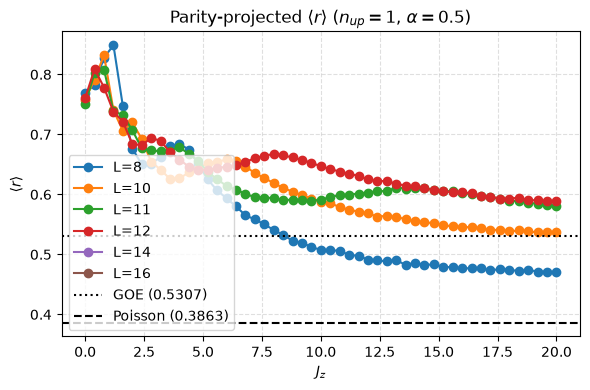

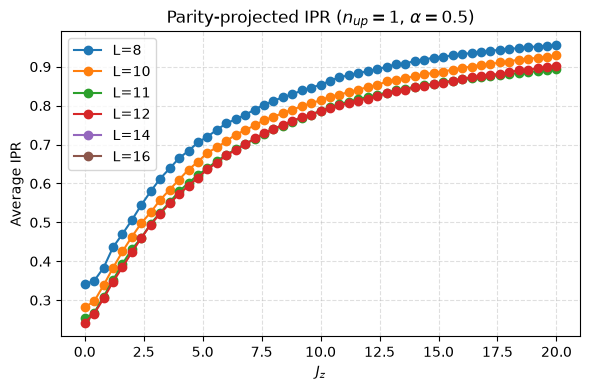

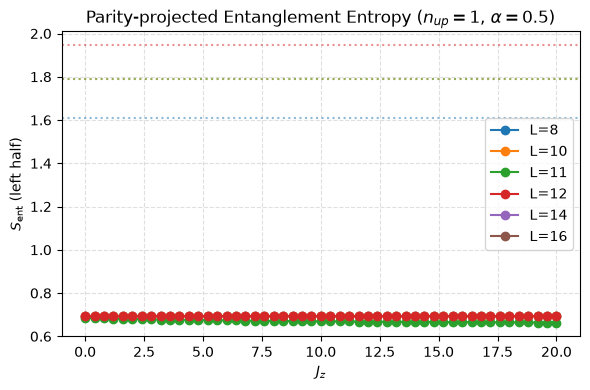

In [2]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------
output_dir = "MBL"
L_values = [8, 10, 11, 12, 14, 16]
alpha = 0.5
W = 0.2
n_up = 1

# Pre-load data into dictionaries to avoid reading disk repeatedly
data_dict = {}
page_dict = {}

for L in L_values:
    sweep_file = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W{W}.csv")
    page_file = os.path.join(output_dir, f"page_estimates_L{L}.csv")

    if os.path.exists(sweep_file):
        df = pd.read_csv(sweep_file)
        data_dict[L] = df[df["n_up"] == n_up].sort_values("Jz")

    if os.path.exists(page_file):
        page_df = pd.read_csv(page_file).set_index("n_up")
        if n_up in page_df.index:
            page_dict[L] = page_df.loc[n_up, "S_max_estimate"]


# ------------------------------------------------------------
# 1. Plot <r> vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["Jz"], sub["r_mean"], marker="o", label=f"L={L}")

plt.axhline(0.5307, linestyle=":", color="k", label="GOE (0.5307)")
plt.axhline(0.3863, linestyle="--", color="k", label="Poisson (0.3863)")
plt.xlabel(r"$J_z$")
plt.ylabel(r"$\langle r\rangle$")
plt.title(
    rf"Parity-projected $\langle r\rangle$ ($n_{{up}}={n_up}$, $\alpha={alpha}$)"
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. Plot IPR vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["Jz"], sub["ipr_mean"], marker="o", label=f"L={L}")

plt.xlabel(r"$J_z$")
plt.ylabel("Average IPR")
plt.title(rf"Parity-projected IPR ($n_{{up}}={n_up}$, $\alpha={alpha}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Plot Entanglement Entropy vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    (line,) = plt.plot(sub["Jz"], sub["S_mean"], marker="o", label=f"L={L}")

    # Matching-colored dotted reference line for Page estimate of each L
    if L in page_dict:
        plt.axhline(
            page_dict[L], linestyle=":", color=line.get_color(), alpha=0.5
        )

plt.xlabel(r"$J_z$")
plt.ylabel(r"$S_{\rm ent}$ (left half)")
plt.title(
    rf"Parity-projected Entanglement Entropy ($n_{{up}}={n_up}$, $\alpha={alpha}$)"
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

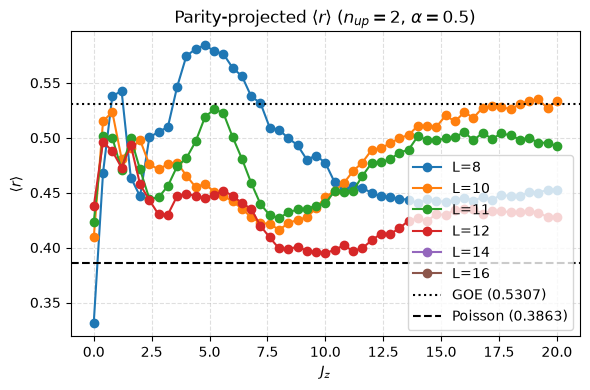

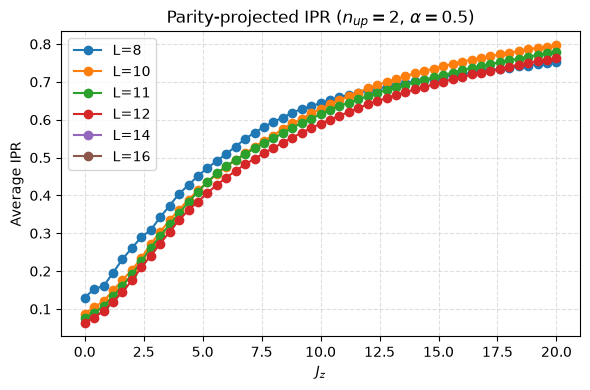

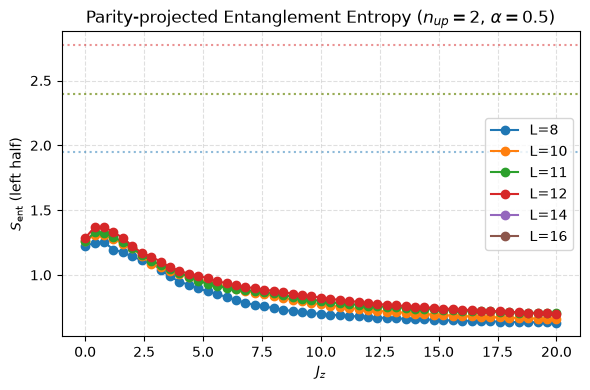

In [6]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------
output_dir = "MBL"
L_values = [8, 10, 11, 12, 14, 16]
alpha = 0.5
W = 0.2
n_up = 2

# Pre-load data into dictionaries to avoid reading disk repeatedly
data_dict = {}
page_dict = {}

for L in L_values:
    sweep_file = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W{W}.csv")
    page_file = os.path.join(output_dir, f"page_estimates_L{L}.csv")

    if os.path.exists(sweep_file):
        df = pd.read_csv(sweep_file)
        data_dict[L] = df[df["n_up"] == n_up].sort_values("Jz")

    if os.path.exists(page_file):
        page_df = pd.read_csv(page_file).set_index("n_up")
        if n_up in page_df.index:
            page_dict[L] = page_df.loc[n_up, "S_max_estimate"]


# ------------------------------------------------------------
# 1. Plot <r> vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["Jz"], sub["r_mean"], marker="o", label=f"L={L}")

plt.axhline(0.5307, linestyle=":", color="k", label="GOE (0.5307)")
plt.axhline(0.3863, linestyle="--", color="k", label="Poisson (0.3863)")
plt.xlabel(r"$J_z$")
plt.ylabel(r"$\langle r\rangle$")
plt.title(
    rf"Parity-projected $\langle r\rangle$ ($n_{{up}}={n_up}$, $\alpha={alpha}$)"
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. Plot IPR vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["Jz"], sub["ipr_mean"], marker="o", label=f"L={L}")

plt.xlabel(r"$J_z$")
plt.ylabel("Average IPR")
plt.title(rf"Parity-projected IPR ($n_{{up}}={n_up}$, $\alpha={alpha}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Plot Entanglement Entropy vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    (line,) = plt.plot(sub["Jz"], sub["S_mean"], marker="o", label=f"L={L}")

    # Matching-colored dotted reference line for Page estimate of each L
    if L in page_dict:
        plt.axhline(
            page_dict[L], linestyle=":", color=line.get_color(), alpha=0.5
        )

plt.xlabel(r"$J_z$")
plt.ylabel(r"$S_{\rm ent}$ (left half)")
plt.title(
    rf"Parity-projected Entanglement Entropy ($n_{{up}}={n_up}$, $\alpha={alpha}$)"
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

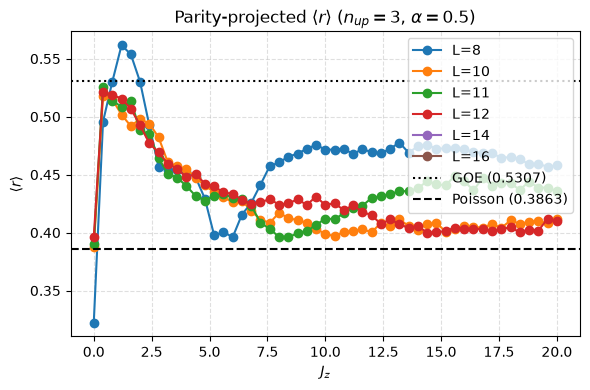

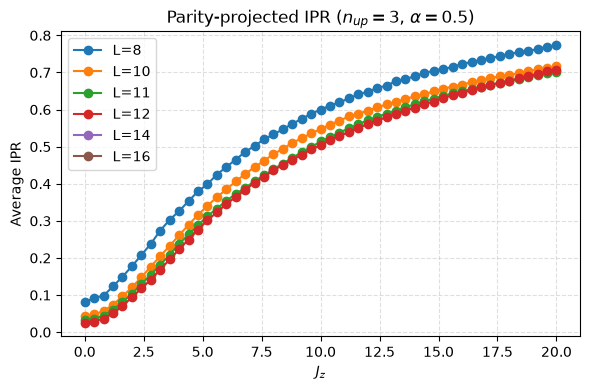

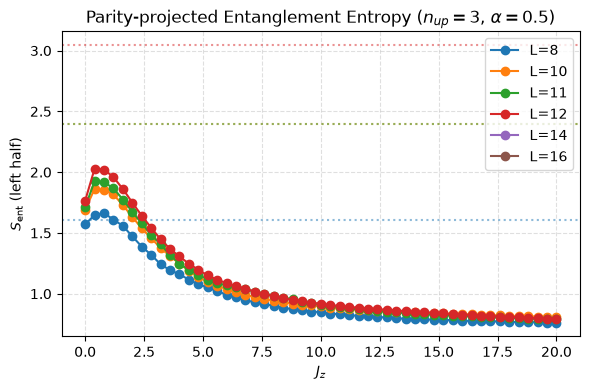

In [7]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------
output_dir = "MBL"
L_values = [8, 10, 11, 12, 14, 16]
alpha = 0.5
W = 0.2
n_up = 3

# Pre-load data into dictionaries to avoid reading disk repeatedly
data_dict = {}
page_dict = {}

for L in L_values:
    sweep_file = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W{W}.csv")
    page_file = os.path.join(output_dir, f"page_estimates_L{L}.csv")

    if os.path.exists(sweep_file):
        df = pd.read_csv(sweep_file)
        data_dict[L] = df[df["n_up"] == n_up].sort_values("Jz")

    if os.path.exists(page_file):
        page_df = pd.read_csv(page_file).set_index("n_up")
        if n_up in page_df.index:
            page_dict[L] = page_df.loc[n_up, "S_max_estimate"]


# ------------------------------------------------------------
# 1. Plot <r> vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["Jz"], sub["r_mean"], marker="o", label=f"L={L}")

plt.axhline(0.5307, linestyle=":", color="k", label="GOE (0.5307)")
plt.axhline(0.3863, linestyle="--", color="k", label="Poisson (0.3863)")
plt.xlabel(r"$J_z$")
plt.ylabel(r"$\langle r\rangle$")
plt.title(
    rf"Parity-projected $\langle r\rangle$ ($n_{{up}}={n_up}$, $\alpha={alpha}$)"
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. Plot IPR vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    plt.plot(sub["Jz"], sub["ipr_mean"], marker="o", label=f"L={L}")

plt.xlabel(r"$J_z$")
plt.ylabel("Average IPR")
plt.title(rf"Parity-projected IPR ($n_{{up}}={n_up}$, $\alpha={alpha}$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Plot Entanglement Entropy vs Jz for varying L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    (line,) = plt.plot(sub["Jz"], sub["S_mean"], marker="o", label=f"L={L}")

    # Matching-colored dotted reference line for Page estimate of each L
    if L in page_dict:
        plt.axhline(
            page_dict[L], linestyle=":", color=line.get_color(), alpha=0.5
        )

plt.xlabel(r"$J_z$")
plt.ylabel(r"$S_{\rm ent}$ (left half)")
plt.title(
    rf"Parity-projected Entanglement Entropy ($n_{{up}}={n_up}$, $\alpha={alpha}$)"
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

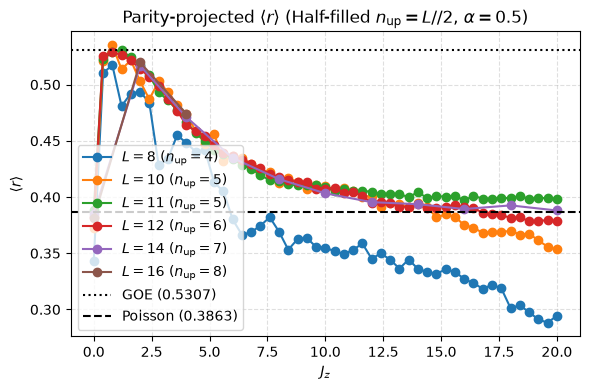

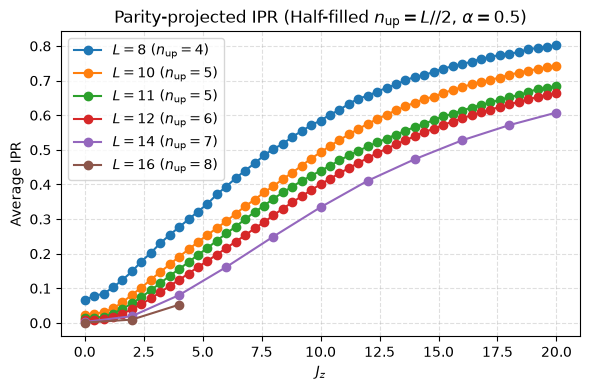

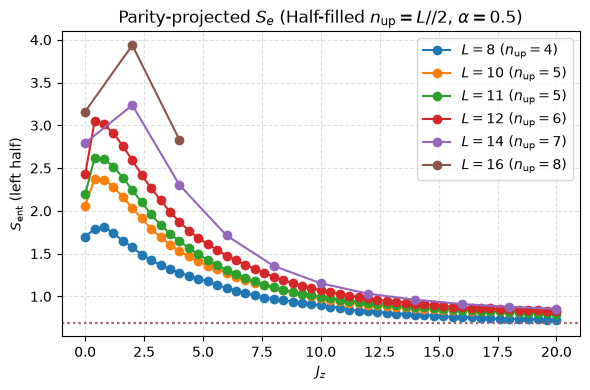

In [5]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------
output_dir = "MBL"
L_values = [8, 10, 11, 12, 14, 16]
alpha = 0.5
W = 0.2

# Pre-load data into dictionaries for half-filling sectors
data_dict = {}
page_dict = {}

for L in L_values:
    n_up = L // 2  # Dynamic half-filling sector for each L

    sweep_file = os.path.join(output_dir, f"sweep_L{L}_alpha{alpha}_W{W}.csv")
    page_file = os.path.join(output_dir, f"page_estimates_L{L}.csv")

    if os.path.exists(sweep_file):
        df = pd.read_csv(sweep_file)
        # Filter for n_up = L // 2
        data_dict[L] = df[df["n_up"] == n_up].sort_values("Jz")

    if os.path.exists(page_file):
        page_df = pd.read_csv(page_file).set_index("n_up")
        if n_up in page_df.index:
            page_dict[L] = page_df.loc[n_up, "S_max_estimate"]


# ------------------------------------------------------------
# 1. Plot <r> vs Jz for half-filling across L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    n_up = L // 2
    plt.plot(
        sub["Jz"],
        sub["r_mean"],
        marker="o",
        label=rf"$L={L}\ (n_{{\rm up}}={n_up})$",
    )

plt.axhline(0.5307, linestyle=":", color="k", label="GOE (0.5307)")
plt.axhline(0.3863, linestyle="--", color="k", label="Poisson (0.3863)")
plt.xlabel(r"$J_z$")
plt.ylabel(r"$\langle r\rangle$")
plt.title(
    rf"Parity-projected $\langle r\rangle$ (Half-filled $n_{{\rm up}}=L//2$, $\alpha={alpha}$)"
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. Plot IPR vs Jz for half-filling across L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    n_up = L // 2
    plt.plot(
        sub["Jz"],
        sub["ipr_mean"],
        marker="o",
        label=rf"$L={L}\ (n_{{\rm up}}={n_up})$",
    )

plt.xlabel(r"$J_z$")
plt.ylabel("Average IPR")
plt.title(
    rf"Parity-projected IPR (Half-filled $n_{{\rm up}}=L//2$, $\alpha={alpha}$)"
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Plot Entanglement Entropy vs Jz for half-filling across L
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))

for L, sub in data_dict.items():
    n_up = L // 2
    (line,) = plt.plot(
        sub["Jz"],
        sub["S_mean"],
        marker="o",
        label=rf"$L={L}\ (n_{{\rm up}}={n_up})$",
    )

    # Plot Page estimate reference line corresponding to this L's half-filled sector
    if L in page_dict:
        plt.axhline(
            page_dict[L], linestyle=":", color=line.get_color(), alpha=0.5
        )

plt.xlabel(r"$J_z$")
plt.ylabel(r"$S_{\rm ent}$ (left half)")
plt.title(
    rf"Parity-projected $S_e$ (Half-filled $n_{{\rm up}}=L//2$, $\alpha={alpha}$)"
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

### $\alpha$ sweep

#### Half-filled case

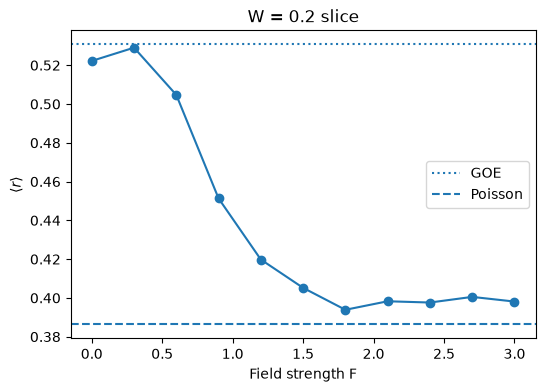

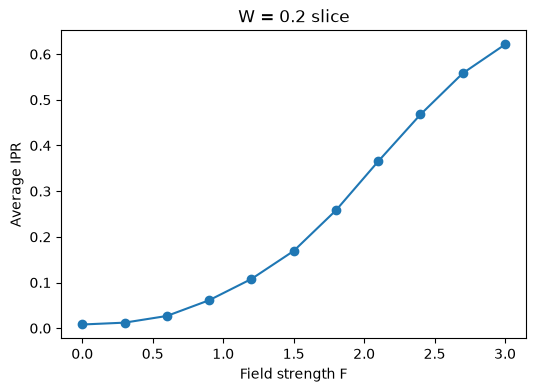

In [4]:
# ============================================================
# Imports
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from itertools import combinations
from scipy.linalg import eigh


# ============================================================
# Basis: half-filled sector
# ============================================================

def half_filled_basis(L):
    """
    Generate all spin configurations with L/2 up spins.
    
    State convention:
    1 = spin up
    0 = spin down
    """

    basis = []

    for ups in combinations(range(L), L//2):

        state = [0]*L

        for i in ups:
            state[i] = 1

        basis.append(tuple(state))

    return basis



def basis_index(basis):

    return {
        state:i for i,state in enumerate(basis)
    }



# ============================================================
# Heisenberg Hamiltonian
# ============================================================
def build_heisenberg(L, J0=1.0, Jz=1.0, F=0.0, h=None):
    """
    Anisotropic Heisenberg (XXZ) Hamiltonian with tilt:

    H = sum_j [ J0 (SxSx + SySy) + Jz SzSz ]_{j,j+1}
        + sum_j F*j*Sz_j
        + sum_j h_j*Sz_j

    Restricted to half-filled sector.

    Parameters
    ----------
    L  : system size
    J0 : XY (flip-flop) coupling
    Jz : Ising (ZZ) coupling
    F  : linear tilt field strength
    h  : array of random on-site fields (optional)

    Returns
    -------
    H, basis
    """

    basis = half_filled_basis(L)
    index = basis_index(basis)

    dim = len(basis)

    H = np.zeros((dim,dim),dtype=float)


    for n,state in enumerate(basis):


        # -----------------------------
        # on-site Sz terms: tilt + random field
        # -----------------------------

        for i in range(L):

            sz = 0.5 if state[i]==1 else -0.5

            # linear tilt field F*j*Sz_j
            H[n,n] += F*i*sz

            # random field h_j*Sz_j
            if h is not None:
                H[n,n] += h[i]*sz



        # -----------------------------
        # nearest-neighbor XXZ terms
        # -----------------------------

        for i in range(L-1):

            si = 1 if state[i]==1 else -1
            sj = 1 if state[i+1]==1 else -1


            # Jz SzSz contribution

            H[n,n] += Jz*0.25*si*sj



            # J0 (SxSx + SySy)
            # flips neighboring opposite spins

            if state[i] != state[i+1]:


                new_state = list(state)

                new_state[i],new_state[i+1] = (
                    new_state[i+1],
                    new_state[i]
                )

                new_state = tuple(new_state)

                m = index[new_state]


                H[m,n] += J0*0.5


    return H,basis



# ============================================================
# Diagonalization
# ============================================================

def diagonalize(H):

    evals,evecs = eigh(H)

    return evals,evecs



# ============================================================
# Select middle of spectrum
# ============================================================

def middle_spectrum(evals,evecs,frac=0.2):
    """
    Keep fraction of states around the middle energy.
    """

    N=len(evals)

    start=int(N*(0.5-frac/2))
    end  =int(N*(0.5+frac/2))


    return evals[start:end], evecs[:,start:end]



# ============================================================
# Level statistics
# ============================================================

def level_spacing_ratio(evals):

    evals=np.sort(evals)

    spacings=np.diff(evals)


    r=[]

    for i in range(len(spacings)-1):

        r.append(
            min(spacings[i],spacings[i+1]) /
            max(spacings[i],spacings[i+1])
        )


    return np.mean(r)



# ============================================================
# Inverse participation ratio
# ============================================================

def compute_IPR(evecs):
    """
    IPR = sum_i |psi_i|^4
    """

    ipr=[]


    for n in range(evecs.shape[1]):

        psi=evecs[:,n]

        ipr.append(
            np.sum(np.abs(psi)**4)
        )


    return np.array(ipr)



# ============================================================
# Single disorder realization
# ============================================================

def analyze_realization(L,W,J0=1.0,Jz=1.0,F=0.0,frac=0.2):
    """
    One disorder realization.

    h_i uniform[-W,W]
    """

    h=np.random.uniform(-W,W,L)


    H,basis = build_heisenberg(
        L=L,
        J0=J0,
        Jz=Jz,
        F=F,
        h=h
    )


    evals,evecs = diagonalize(H)


    evals_mid,evecs_mid = middle_spectrum(
        evals,
        evecs,
        frac
    )


    r = level_spacing_ratio(evals_mid)

    ipr = np.mean(
        compute_IPR(evecs_mid)
    )


    return r,ipr

# ============================================================
# Disorder averaging
# ============================================================

def disorder_average(
        L,
        W,
        realizations=50,
        J0=1.0,
        Jz=1.0,
        F=0.0,
        frac=1):


    r_values=[]
    ipr_values=[]


    for _ in range(realizations):

        r,ipr = analyze_realization(
            L=L,
            W=W,
            J0=J0,
            Jz=Jz,
            F=F,
            frac=frac
        )

        r_values.append(r)
        ipr_values.append(ipr)


    return (
        np.mean(r_values),
        np.std(r_values),
        np.mean(ipr_values),
        np.std(ipr_values)
    )



# ============================================================
# Example: reproduce r statistics vs disorder
# ============================================================

L=11

# W_values=np.linspace(0,7,21)
W_values=[0.2]


r_results=[]
ipr_results=[]


for W in W_values:

    r_mean,r_std,ipr_mean,ipr_std = disorder_average(
        L=L,
        W=W,
        realizations=120,
        J0=1,
        Jz=1,
        F=0.5,
        frac=1
    )


    r_results.append(r_mean)
    ipr_results.append(ipr_mean)


# ============================================================
# F sweep at fixed W=0.2
# ============================================================

F_values = np.linspace(0, 3, 11)

r_results_F = []
ipr_results_F = []

for F in F_values:

    r_mean, r_std, ipr_mean, ipr_std = disorder_average(
        L=L,
        W=0.2,
        realizations=120,
        J0=1,
        Jz=1,
        F=F,
        frac=0.5
    )

    r_results_F.append(r_mean)
    ipr_results_F.append(ipr_mean)


plt.figure(figsize=(6,4))
plt.plot(F_values, r_results_F, marker="o")
plt.axhline(0.5307, linestyle=":", label="GOE")
plt.axhline(0.3863, linestyle="--", label="Poisson")
plt.xlabel("Field strength F")
plt.ylabel(r"$\langle r\rangle$")
plt.title("W = 0.2 slice")
plt.legend()
plt.show()


plt.figure(figsize=(6,4))
plt.plot(F_values, ipr_results_F, marker="o")
plt.xlabel("Field strength F")
plt.ylabel("Average IPR")
plt.title("W = 0.2 slice")
plt.show()

#### Single excitation case

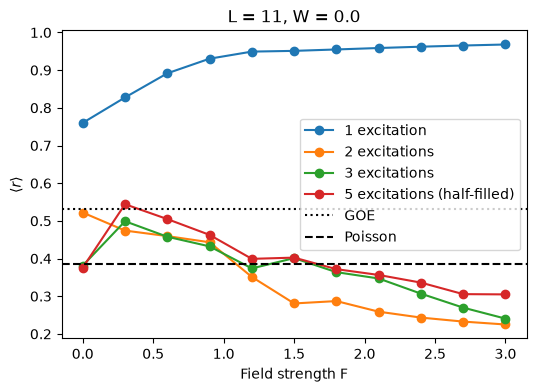

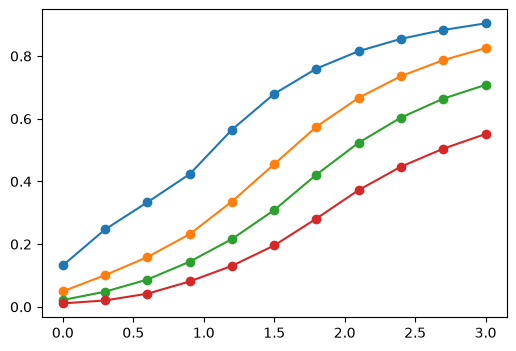

In [24]:
# ============================================================
# Imports
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from itertools import combinations
from scipy.linalg import eigh


# ============================================================
# Basis: fixed number of excitations (up spins)
# ============================================================

def fixed_excitation_basis(L, n_up):
    """
    Generate all spin configurations with n_up up spins.

    n_up = L//2  -> half-filled sector
    n_up = 1     -> single-excitation sector

    State convention:
    1 = spin up
    0 = spin down
    """

    basis = []

    for ups in combinations(range(L), n_up):

        state = [0]*L

        for i in ups:
            state[i] = 1

        basis.append(tuple(state))

    return basis



def basis_index(basis):

    return {
        state:i for i,state in enumerate(basis)
    }



# ============================================================
# Heisenberg Hamiltonian (generalized to n_up excitations)
# ============================================================
def build_heisenberg(L, n_up=None, J0=1.0, Jz=1.0, F=0.0, h=None):
    """
    Anisotropic Heisenberg (XXZ) Hamiltonian with tilt:

    H = sum_j [ J0 (SxSx + SySy) + Jz SzSz ]_{j,j+1}
        + sum_j F*j*Sz_j
        + sum_j h_j*Sz_j

    Restricted to a fixed n_up (excitation number) sector.

    Parameters
    ----------
    L    : system size
    n_up : number of up spins (excitations).
           Default: L//2 (half-filled sector)
           Set n_up=1 for the single-excitation sector.
    J0   : XY (flip-flop) coupling
    Jz   : Ising (ZZ) coupling
    F    : linear tilt field strength
    h    : array of random on-site fields (optional)

    Returns
    -------
    H, basis
    """

    if n_up is None:
        n_up = L // 2

    basis = fixed_excitation_basis(L, n_up)
    index = basis_index(basis)

    dim = len(basis)

    H = np.zeros((dim,dim),dtype=float)


    for n,state in enumerate(basis):


        # -----------------------------
        # on-site Sz terms: tilt + random field
        # -----------------------------

        for i in range(L):

            sz = 0.5 if state[i]==1 else -0.5

            # linear tilt field F*j*Sz_j
            H[n,n] += F*i*sz

            # random field h_j*Sz_j
            if h is not None:
                H[n,n] += h[i]*sz



        # -----------------------------
        # nearest-neighbor XXZ terms
        # -----------------------------

        for i in range(L-1):

            si = 1 if state[i]==1 else -1
            sj = 1 if state[i+1]==1 else -1


            # Jz SzSz contribution

            H[n,n] += Jz*0.25*si*sj



            # J0 (SxSx + SySy)
            # flips neighboring opposite spins

            if state[i] != state[i+1]:


                new_state = list(state)

                new_state[i],new_state[i+1] = (
                    new_state[i+1],
                    new_state[i]
                )

                new_state = tuple(new_state)

                m = index[new_state]


                H[m,n] += J0*0.5


    return H,basis



# ============================================================
# Diagonalization
# ============================================================

def diagonalize(H):

    evals,evecs = eigh(H)

    return evals,evecs



# ============================================================
# Select middle of spectrum
# ============================================================

def middle_spectrum(evals,evecs,frac=0.2):
    """
    Keep fraction of states around the middle energy.
    """

    N=len(evals)

    start=int(N*(0.5-frac/2))
    end  =int(N*(0.5+frac/2))


    return evals[start:end], evecs[:,start:end]



# ============================================================
# Level statistics
# ============================================================

def level_spacing_ratio(evals):

    evals=np.sort(evals)

    spacings=np.diff(evals)


    r=[]

    for i in range(len(spacings)-1):

        r.append(
            min(spacings[i],spacings[i+1]) /
            max(spacings[i],spacings[i+1])
        )


    return np.mean(r)



# ============================================================
# Inverse participation ratio
# ============================================================

def compute_IPR(evecs):
    """
    IPR = sum_i |psi_i|^4
    """

    ipr=[]


    for n in range(evecs.shape[1]):

        psi=evecs[:,n]

        ipr.append(
            np.sum(np.abs(psi)**4)
        )


    return np.array(ipr)



# ============================================================
# Single disorder realization
# ============================================================

def analyze_realization(L,W,n_up=None,J0=1.0,Jz=1.0,F=0.0,frac=0.2):
    """
    One disorder realization.

    h_i uniform[-W,W]

    n_up : excitation number sector (None -> half-filled)
    """

    h=np.random.uniform(-W,W,L)


    H,basis = build_heisenberg(
        L=L,
        n_up=n_up,
        J0=J0,
        Jz=Jz,
        F=F,
        h=h
    )


    evals,evecs = diagonalize(H)


    evals_mid,evecs_mid = middle_spectrum(
        evals,
        evecs,
        frac
    )


    # Single-excitation sector has dim = L, which can be too
    # small for a meaningful gap-ratio average once you also
    # restrict to the "middle" — guard against too-few levels.
    if len(evals_mid) < 3:
        r = np.nan
    else:
        r = level_spacing_ratio(evals_mid)

    ipr = np.mean(
        compute_IPR(evecs_mid)
    )


    return r,ipr

# ============================================================
# Disorder averaging
# ============================================================

def disorder_average(
        L,
        W,
        n_up=None,
        realizations=50,
        J0=1.0,
        Jz=1.0,
        F=0.0,
        frac=1):


    r_values=[]
    ipr_values=[]


    for _ in range(realizations):

        r,ipr = analyze_realization(
            L=L,
            W=W,
            n_up=n_up,
            J0=J0,
            Jz=Jz,
            F=F,
            frac=frac
        )

        r_values.append(r)
        ipr_values.append(ipr)


    return (
        np.nanmean(r_values),
        np.nanstd(r_values),
        np.mean(ipr_values),
        np.std(ipr_values)
    )


# ============================================================
# F sweep across multiple excitation-number sectors, fixed L
# ============================================================

L = 11
F_values = np.linspace(0, 3, 11)

# Sectors to compare: 1, 2, 3 excitations, and half-filling
n_up_values = [1, 2, 3, L // 2]

results = {}   # n_up -> dict with 'r' and 'ipr' lists

for n_up in n_up_values:

    r_results = []
    ipr_results = []

    for F in F_values:

        r_mean, r_std, ipr_mean, ipr_std = disorder_average(
            L=L, W=0.0, n_up=n_up,
            realizations=1,
            J0=1, Jz=1, F=F, frac=1
        )

        r_results.append(r_mean)
        ipr_results.append(ipr_mean)

    results[n_up] = {
        "r": r_results,
        "ipr": ipr_results
    }


# ------------------------------------------------------------
# Plot <r> for all sectors together
# ------------------------------------------------------------

plt.figure(figsize=(6,4))

for n_up in n_up_values:
    label = f"{n_up} excitation" if n_up == 1 else f"{n_up} excitations"
    if n_up == L // 2:
        label += " (half-filled)"
    plt.plot(F_values, results[n_up]["r"], marker="o", label=label)

plt.axhline(0.5307, linestyle=":", color="k", label="GOE")
plt.axhline(0.3863, linestyle="--", color="k", label="Poisson")
plt.xlabel("Field strength F")
plt.ylabel(r"$\langle r\rangle$")
plt.title(f"L = {L}, W = 0.0")
plt.legend()
plt.show()


# ------------------------------------------------------------
# Plot IPR for all sectors together
# ------------------------------------------------------------

plt.figure(figsize=(6,4))

for n_up in n_up_values:
    label = f"{n_up} excitation" if n_up == 1 else f"{n_up} excitations"
    if n_up == L // 2:
        label += " (half-filled)"
    plt.plot(F_values, results[n_up]["ipr"], marker="o", label=label)
